### init

In [19]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import wandb


n_seg_name = r"$N_{\mathrm{seg}}$"
n_seg_name = r"$N$"
seg_deg_name = r"$m$"
free_model_name = "FLC"
pretrained_model_name = "ALC"

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX 
                            using \showthe\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


# fig_width_pt = 234.8  # Get this from LaTeX using \showthe\columnwidth
fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    # Use LaTeX to write all text
    "text.usetex": True,
    # "text.latex.preamble": r"\usepackage{amsmath}",  # This provides \text{}
    # "text.latex.preamble": r'\usepackage{amsfonts}',
    "font.family": "Nimbus Sans",
    # Use 10pt font in plots, to match 10pt font in document
    "axes.labelsize": 10,
    "font.size": 10,
    # Make the legend/label fonts a little smaller
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


### Load sampling results

In [5]:
from pathlib import Path

sampling_files = [
    "result/sampling/wino_m_psmile.csv",
    "result/sampling/wino_m_sghmc.csv",
    "result/sampling/wino_s_psmile.csv",
    "result/sampling/wino_s_sghmc.csv",
    "result/sampling/lora_obqa_psmile_replications.csv",
    "result/sampling/lora_arc_easy_psmile_replications.csv",
    "result/sampling/lora_arc_chall_psmile_replications.csv",
]

rows = []
for file_path in sampling_files:
    df_s = pd.read_csv(file_path)

    # Determine dataset and selection logic
    fname = Path(file_path).name
    if "obqa" in fname:
        dataset = "obqa"
        step_size = 0.0005
    elif "arc_easy" in fname:
        dataset = "ARC-Easy"
        step_size = 0.0005
    elif "arc_chall" in fname:
        dataset = "ARC-Challenge"
        step_size = 0.0005
    else:
        # Original logic for winogrande files
        dataset = "winogrande_m" if "wino_m" in file_path else "winogrande_s"
        ref = df_s[df_s["rng"] == 400]
        if ref.empty:
            print(f"Skipping {file_path}: no rng=400 row found")
            continue
        step_size = ref.iloc[0]["training_sampler_step_size"]

    # Filter by the chosen step size
    df_sel = df_s[df_s["training_sampler_step_size"] == step_size].copy()

    # Build the same core structure used in our extracted dataframe
    for _, r in df_sel.iterrows():
        rows.append(
            {
                "Id": str(r.get("experiment", Path(file_path).stem)),
                "CurveSpace": -1,
                "CpFix": "sampling",
                "NumPretrained": -1,
                "Jitter": -1,
                "Seed": int(r.get("rng", -1)) if pd.notna(r.get("rng", np.nan)) else -1,
                "WeightDecay": -1,
                "Dataset": dataset,
                "BmaMode": "Sampling",
                "DS_Sampling": str(r.get("training_sampler_name", "noisysmile")),
                "DS_Mode": "sampler",
                "DS_WindowSize": -1,
                "EntropyMaxScale": -1,
                "NumSteps": -1,
                "LoraMode": "Sampling",
                "CurveMode": "Sampling",
                "LoraRank": -1,
                "RegularizationMode": False,
                "Gravity": -1,
                "EnergyWeakening": -1,
                "Tsample": "sampling",
                "LoraRho": -1,
                "LoraRhoS": -1,
                "RhoFrequency": -1,
                "CurveSegmentDegree": -1,
                "NCurveSegment": 0,
                "OpenEndSegment": False,
                "bezierLength": 0,
                "acc": r.get("PredPerf_sampling_bma_accuracy", np.nan),
                "ece": r.get("Calibration_sampling_calibration_error", np.nan),
                "ll": r.get("LPPD_sampling_LPPD", np.nan),
                "test_mean_entropy_ppd": np.nan,
                "test_mutual_information_ppd": np.nan,
                "test_std_entropy_along_curve": np.nan,
                "test_mean_entropy_along_curve": np.nan,
                "Method": str(r.get("training_sampler_name", "noisysmile")),
                "SamplerStepSize": step_size,
                "SourceFile": fname,
            }
        )

    print(f"{fname}: target_step_size={step_size}, rows_kept={len(df_sel)}")

df_sampling = pd.DataFrame(rows)

out_path = "result/sampling/sampling_merged_stepfiltered.csv"
df_sampling.to_csv(out_path, index=False)
print(f"Saved merged sampling dataframe to {out_path} with {len(df_sampling)} rows")

df_sampling = df_sampling.melt(
    id_vars=[c for c in df_sampling.columns if c not in ["acc", "ll", "ece"]],
    value_vars=["acc", "ll", "ece"],
    var_name="Metric",
    value_name="value",
)
df_sampling.dropna(subset=['value'], inplace=True)

def get_sampling_model_name(m):
    if m == "noisysmile" or "noisysmile" in str(m):
        return "Sampling-PSMILE"
    return "Sampling-SGHMC"

df_sampling["Model"] = df_sampling["Method"].apply(get_sampling_model_name)
df_sampling["NCurveSegment"] = 0

# fix ARC-Challenge dataset ll values (they are all -inf due to a logging bug, but we know they should be around -1.5 to -2.0 based on other datasets and sanity checks)
arc_challenge_mask = (df_sampling["Dataset"] == "ARC-Challenge") & (df_sampling["Metric"] == "ll")
df_sampling.loc[arc_challenge_mask, "value"] -= 0.02  # Set to -0.2 as 8 dps were missing

df_sampling.head()

wino_m_psmile.csv: target_step_size=0.0001, rows_kept=5
wino_m_sghmc.csv: target_step_size=5e-06, rows_kept=5
wino_s_psmile.csv: target_step_size=0.01, rows_kept=5
wino_s_sghmc.csv: target_step_size=0.0001, rows_kept=5
lora_obqa_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_easy_psmile_replications.csv: target_step_size=0.0005, rows_kept=8
lora_arc_chall_psmile_replications.csv: target_step_size=0.0005, rows_kept=5
Saved merged sampling dataframe to result/sampling/sampling_merged_stepfiltered.csv with 41 rows


,Id,CurveSpace,CpFix,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,DS_Sampling,...,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,Method,SamplerStepSize,SourceFile,Metric,value,Model
0,lora_wino_m_div5_20260320-063059,-1,sampling,-1,-1,40,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.830833,Sampling-PSMILE
1,lora_wino_m_div5_20260320-051752,-1,sampling,-1,-1,20,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.831667,Sampling-PSMILE
2,lora_wino_m_div5_20260320-074403,-1,sampling,-1,-1,400,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.835000,Sampling-PSMILE
3,lora_wino_m_div5_20260320-040549,-1,sampling,-1,-1,2,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.832500,Sampling-PSMILE
4,lora_wino_m_div5_2_20260317-211143,-1,sampling,-1,-1,1,-1,winogrande_m,Sampling,noisysmile,...,NaN,NaN,NaN,NaN,noisysmile,0.0001,wino_m_psmile.csv,acc,0.838333,Sampling-PSMILE


### Load ScalaBL rerun

In [6]:
import jax
api = wandb.Api()
scalabl_rows = []
for run in tqdm(api.runs("ddold/ScalaBL-Qwen7B-id"), desc="ScalaBL from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    brier = run.summary.get("final_val_brier", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "ScalaBL", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "ScalaBL", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "ScalaBL", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "brier", "Model": "ScalaBL", "value": brier, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})

for run in tqdm(api.runs("ddold/BLoB-Qwen2.5-7B-id"), desc="BLoB from W&B"):
    if run.state != "finished":
        continue
    dataset = run.config.get("dataset")
    if dataset is None:
        continue

    acc = run.summary.get("final_val_acc", np.nan)
    ece = run.summary.get("final_val_ece", np.nan)
    nll = run.summary.get("final_val_nll", np.nan)
    brier = run.summary.get("final_val_brier", np.nan)
    ll = -nll if pd.notna(nll) else np.nan

    scalabl_rows.append({"Dataset": dataset, "Metric": "acc", "Model": "BLoB", "value": acc, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ece", "Model": "BLoB", "value": ece, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "ll", "Model": "BLoB", "value": ll, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})
    scalabl_rows.append({"Dataset": dataset, "Metric": "brier", "Model": "BLoB", "value": brier, "NCurveSegment": 0, "Seed": run.config.get("seed", -1)})


ref_acc = {
    'winogrande_s':  {'MLE': 78.86, 'MAP': 78.94, 'BLoB_p': 78.66, 'ScalaBL_p': 78.64},
    'ARC-Challenge': {'MLE': 89.53, 'MAP': 88.98, 'BLoB_p': 89.53, 'ScalaBL_p': 90.16},
    'ARC-Easy':      {'MLE': 95.60, 'MAP': 95.73, 'BLoB_p': 96.54, 'ScalaBL_p': 96.26},
    'winogrande_m':  {'MLE': 82.30, 'MAP': 82.09, 'BLoB_p': 82.30, 'ScalaBL_p': 81.42},
    'obqa':          {'MLE': 92.25, 'MAP': 91.72, 'BLoB_p': 91.72, 'ScalaBL_p': 90.90},
    'boolq':         {'MLE': 89.06, 'MAP': 89.04, 'BLoB_p': 89.05, 'ScalaBL_p': 88.48},
}
# Reference NLL values (our ll = -nll, so ref_ll = -ref_nll)
ref_nll = {
    'boolq':         {'MLE': 0.25, 'MAP': 0.25, 'BLoB_p': 0.23, 'ScalaBL_p': 0.24},
    'ARC-Easy':      {'MLE': 0.44, 'MAP': 0.43, 'BLoB_p': 0.10, 'ScalaBL_p': 0.11},
    'ARC-Challenge': {'MLE': 1.05, 'MAP': 1.05, 'BLoB_p': 0.30, 'ScalaBL_p': 0.31},
    'obqa':          {'MLE': 0.38, 'MAP': 0.39, 'BLoB_p': 0.21, 'ScalaBL_p': 0.23},
    'winogrande_s':  {'MLE': 1.94, 'MAP': 1.88, 'BLoB_p': 0.51, 'ScalaBL_p': 0.51},
    'winogrande_m':  {'MLE': 1.20, 'MAP': 1.27, 'BLoB_p': 0.39, 'ScalaBL_p': 0.40},
}
# Reference ECE values (in %, divide by 100)
ref_ece = {
    'winogrande_s':  {'MLE': 20.14, 'MAP': 19.99, 'BLoB_p': 7.88,  'ScalaBL_p': 8.88},
    'ARC-Challenge': {'MLE': 10.11, 'MAP': 10.54, 'BLoB_p': 4.03,  'ScalaBL_p': 5.03},
    'ARC-Easy':      {'MLE': 4.17,  'MAP': 4.08,  'BLoB_p': 1.60,  'ScalaBL_p': 1.78},
    'winogrande_m':  {'MLE': 16.10, 'MAP': 16.42, 'BLoB_p': 5.08,  'ScalaBL_p': 3.64},
    'obqa':          {'MLE': 6.40,  'MAP': 6.61,  'BLoB_p': 2.16,  'ScalaBL_p': 2.43},
    'boolq':         {'MLE': 3.79,  'MAP': 3.81,  'BLoB_p': 1.40,  'ScalaBL_p': 1.96},
}
ref_map = {
    'acc': jax.tree.map(lambda v: v / 100, ref_acc),  # convert % to [0,1]
    'll':  jax.tree.map(lambda v: -v, ref_nll),       # ll = -nll
    'ece': jax.tree.map(lambda v: v / 100, ref_ece),
}
metric_order = ['acc', 'll', 'ece']
df_vi_paper = pd.DataFrame([
        {'Dataset': ds, 'Metric': metric, 'Model': model, 'value': ref_map[metric][ds][model], 'NCurveSegment': 0}
        for ds in ref_acc.keys() for metric in metric_order for model in ['BLoB_p', 'ScalaBL_p']
    ])

df_vi = pd.DataFrame(scalabl_rows)
df_vi.head()


BLoB from W&B: 100%|██████████| 48/48 [00:00<00:00, 31155.46it/s]


,Dataset,Metric,Model,value,NCurveSegment,Seed
0,winogrande_s,acc,ScalaBL,0.793513,0,0
1,winogrande_s,ece,ScalaBL,0.079228,0,0
2,winogrande_s,ll,ScalaBL,-0.511719,0,0
3,winogrande_s,brier,ScalaBL,0.302734,0,0
4,winogrande_s,acc,ScalaBL,0.785601,0,7


### Collect all bezier segments data

We run Modeconnected exp with A(t)B(t) and [1,0,0,1,0, 0,1] fixed control points. 
Then the pretrainedd models are used as DE members and compared against curve training with these fixed control points

In [64]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'we8wq8n7', 'solftkne', 'kru2lo9d' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            NKnots=NCurveSegment + 1,
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

w0kaq8i0: 100%|██████████| 200/200 [00:00<00:00, 276.32it/s, colorful-sweep-6]      
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,2910.0,9.965636e+00,7.180733e+00,2.000000e+00,4.000000,8.000000,16.000000,24.000000
NumPretrained,2910.0,5.054983e+00,3.267137e+00,0.000000e+00,3.000000,5.000000,9.000000,9.000000
Jitter,2910.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,2910.0,1.684600e+03,3.161904e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,2910.0,1.000000e-03,4.337554e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,2910.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,2910.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,2910.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,2910.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,2910.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [65]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [ 8  4  2 24 12  6  3 16]
NumPretrained [9 5 3 2 0]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m' 'boolq']
BmaMode ['PPD' 'DE' 'MAP' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [1 3 2]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
NKnots [9 5 3 2]

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'NKnots'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

### pre analyse

In [39]:
# Build Config label
df_subset = df_clean.copy()

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
# df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['Dataset', 'BmaMode',]]), axis=1)

col_order = df_subset['Dataset'].unique()
col_order.sort()


/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(
/tmp/ipykernel_1623721/918552579.py:17: FutureWarning: Use "auto" to set automatic grayscale colors. From v0.14.0, "gray" will default to matplotlib's definition.
  sns.stripplot(


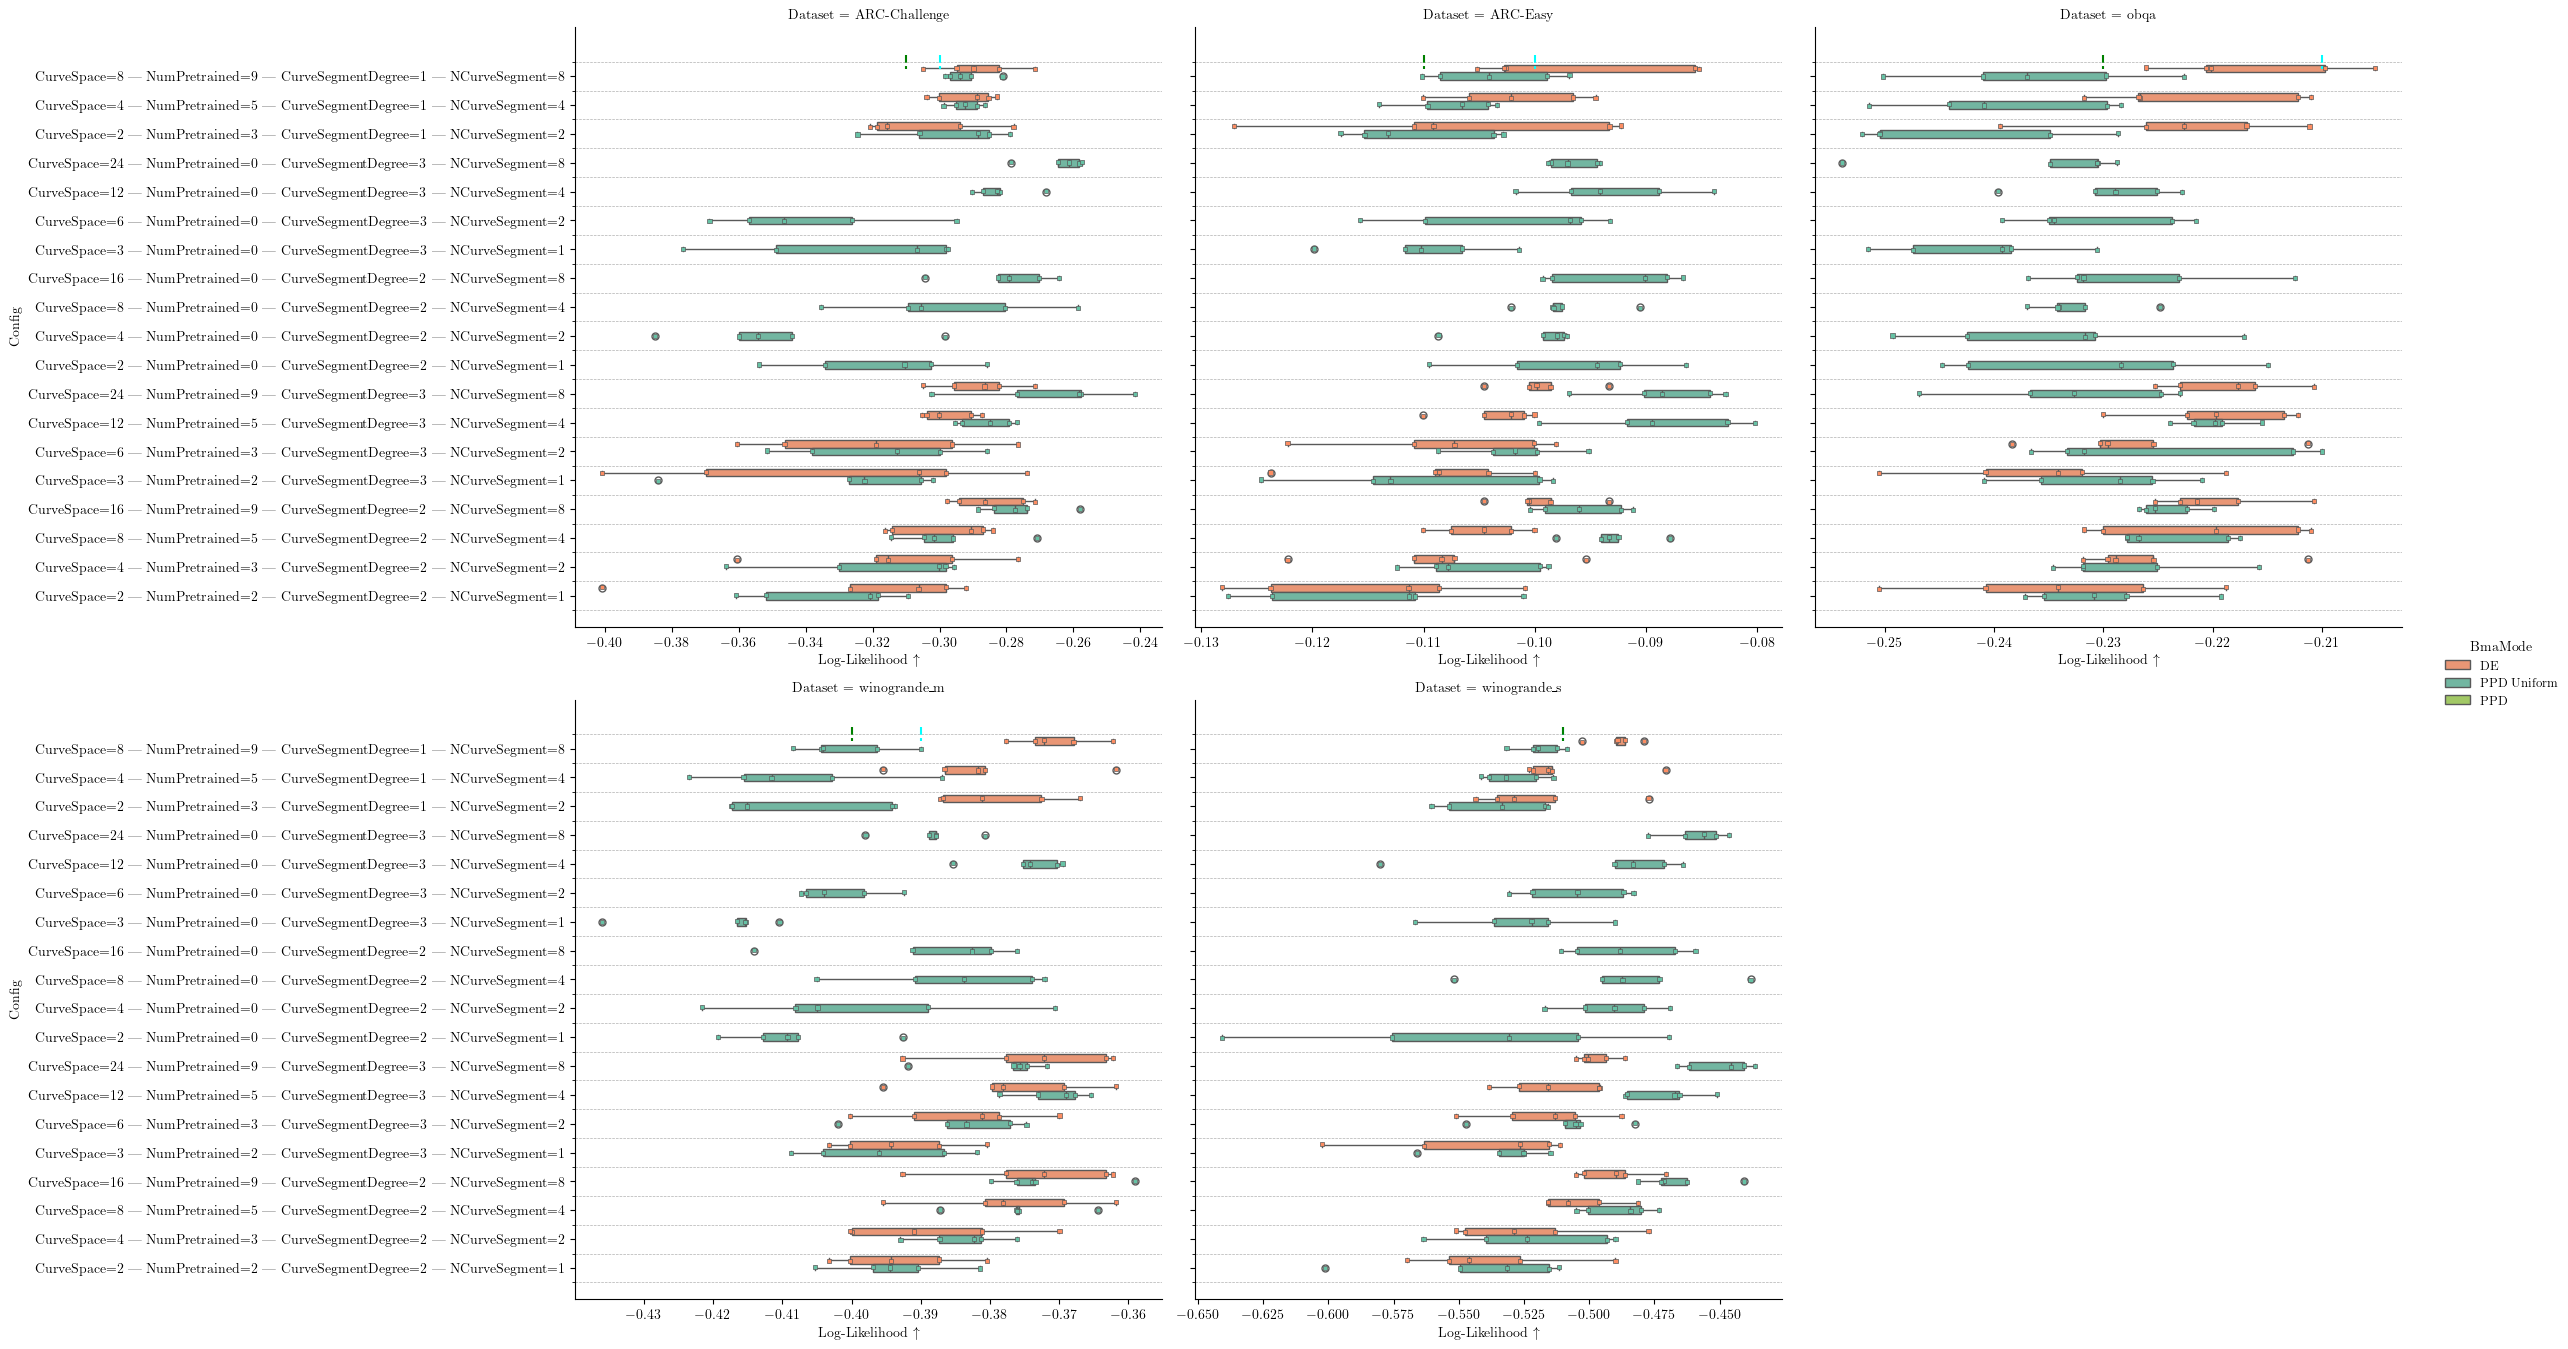

In [40]:
# Filters
df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['Metric'] == 'll')]

hue_order = ['DE', 'PPD Uniform', 'PPD']
cmap = sns.color_palette("Set2")
hue_palette = {'DE': cmap[1], 'PPD Uniform': cmap[0], 'PPD': cmap[4]}

g = sns.catplot(
    data=df_plot, y='Config', x='value', hue='BmaMode', kind='box',
    col='Dataset', palette=hue_palette, col_wrap=3,
    height=figsize[1] * 2, col_order=col_order,
    hue_order=hue_order, aspect=1.2, sharex=False
)

# Overlay strip plots
for ds, ax in g.axes_dict.items():
    sns.stripplot(
        data=df_plot[df_plot['Dataset'] == ds],
        y='Config', x='value', hue='BmaMode',
        ax=ax, palette=hue_palette, dodge=True,
        edgecolor='gray', linewidth=0.5, size=3, marker='s',
        hue_order=hue_order, legend=False
    )
    ax.set_xlabel(r'Log-Likelihood $\uparrow$')

# Draw reference lines (ll only) - horizontal lines become vertical
ref_dict = ref_nll
transform = lambda v: -v

for ds, ax in g.axes_dict.items():
    if ds in ref_dict:
        tick = -0.5 # Config axis tick
        ax.vlines(x=transform(ref_dict[ds]['BLoB']),    ymin=tick-0.25, ymax=tick+0.25,
                  colors='cyan',  linestyles='--', lw=1.5, label='BLoB')
        ax.vlines(x=transform(ref_dict[ds]['ScalaBL']), ymin=tick-0.25, ymax=tick+0.25,
                  colors='green', linestyles='--', lw=1.5, label='ScalaBL')

# Rotate labels not needed for transposed y-axis usually, but keeping general style
for ax in g.axes.flat:
    # ax.tick_params(axis='y', labelrotation=0)
    pass

g.tight_layout()

# grid lines for y-axis (configs)
for ax in g.axes.flat:
    major_ticks = ax.get_yticks()
    if len(major_ticks) > 0:
        minor_ticks = np.arange(start=min(major_ticks) - 0.5, 
                                stop=max(major_ticks) + 1.5, 
                                step=1)
        ax.set_yticks(minor_ticks, minor=True)
        ax.grid(True, axis='y', which='minor', linestyle='--', linewidth=0.5)

### final summary

In [66]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({n_seg_name}={x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({n_seg_name}={x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({n_seg_name}={x['NCurveSegment'] + 1}, {seg_deg_name}={seg_deg})"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [67]:
df_plot['Model'].unique()

array(['ALC($N$=2, $m$=2)', 'ALC($N$=2, $m$=3)', 'ALC($N$=3, $m$=2)',
       'ALC($N$=3, $m$=3)', 'ALC($N$=5, $m$=2)', 'ALC($N$=5, $m$=3)',
       'ALC($N$=9, $m$=2)', 'ALC($N$=9, $m$=3)', 'DE($N$=2)', 'DE($N$=3)',
       'DE($N$=5)', 'DE($N$=9)', 'FLC($N$=2, $m$=2)', 'FLC($N$=2, $m$=3)',
       'FLC($N$=3, $m$=2)', 'FLC($N$=3, $m$=3)', 'FLC($N$=5, $m$=2)',
       'FLC($N$=5, $m$=3)', 'FLC($N$=9, $m$=2)', 'FLC($N$=9, $m$=3)',
       'Linear($N$=3)', 'Linear($N$=5)', 'Linear($N$=9)', 'MAP'],
      dtype=object)

Models set() missing:


/tmp/ipykernel_2061780/3756496497.py:52: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


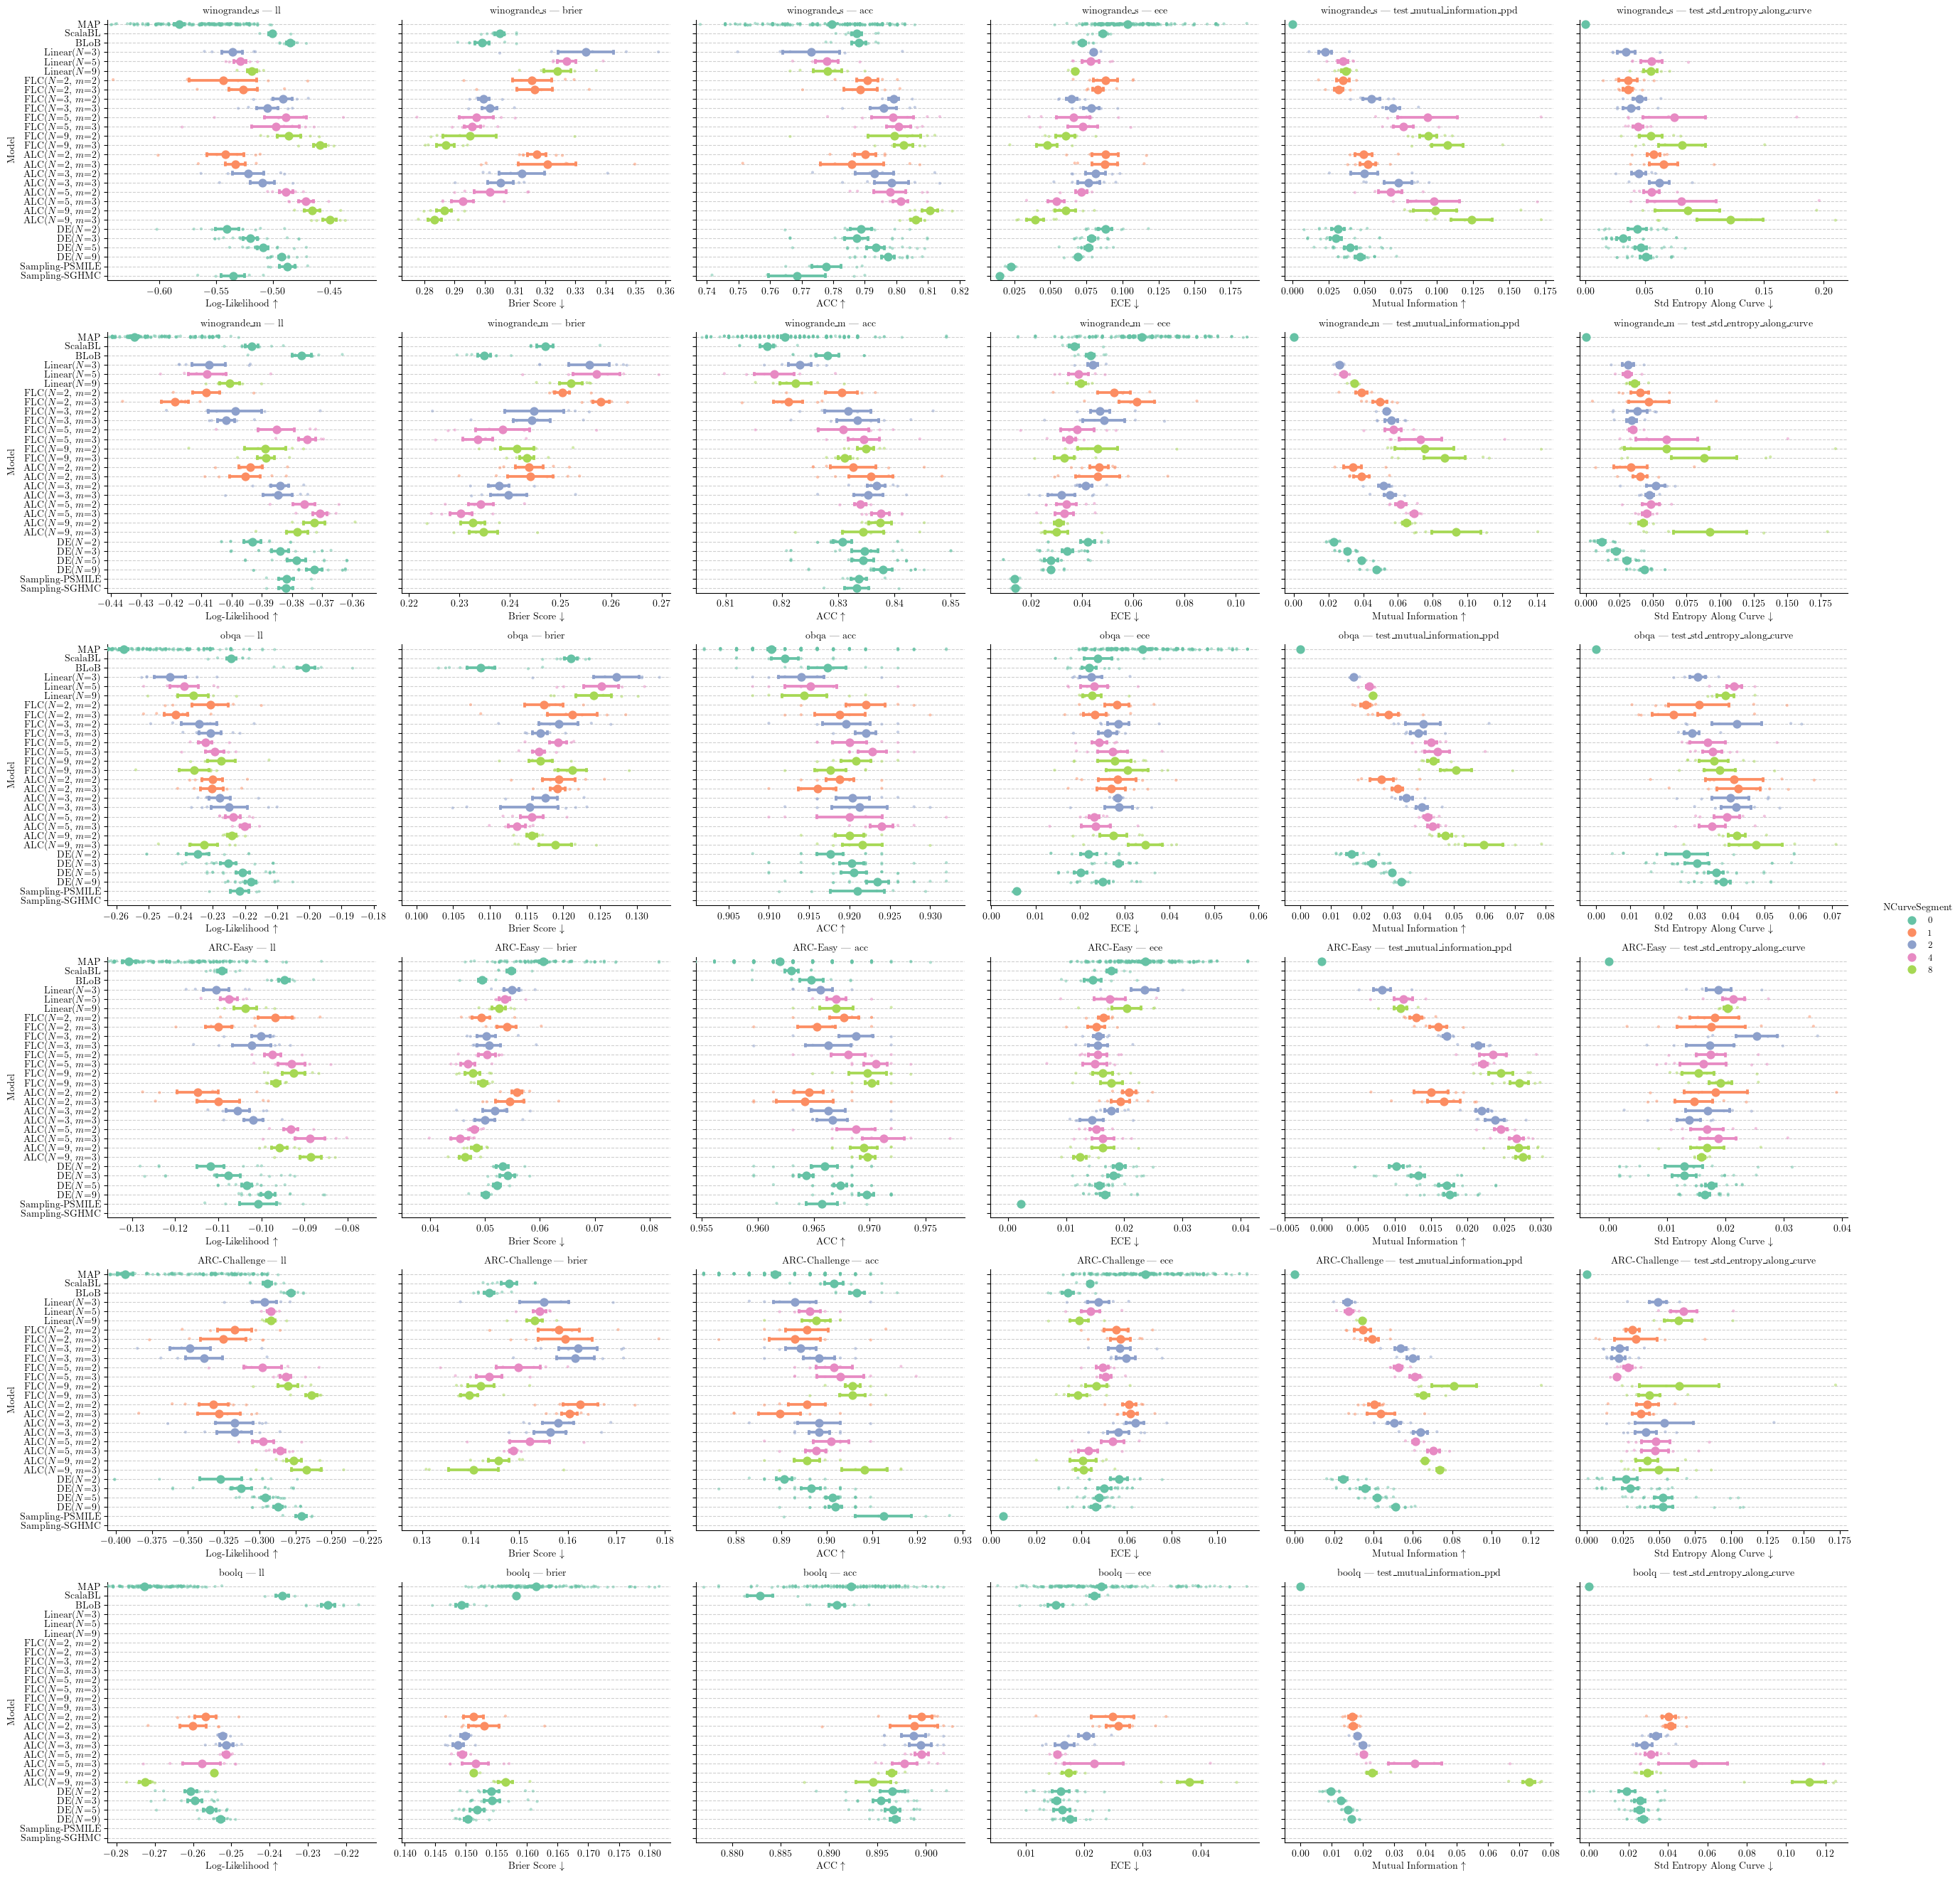

In [72]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi, df_sampling], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = ['MAP', 
         'ScalaBL', 'BLoB', 
         rf'Linear({n_seg_name}=3)', rf'Linear({n_seg_name}=5)', rf'Linear({n_seg_name}=9)', #'OpenLinear(13)',
         rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
         rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=3)', 
        #  'Fix=False, N_{n_seg_name}=12, {seg_deg_name}=m$1', 
        #  'Fix=True, N_{n_seg_name}=12, {seg_deg_name}=1', 
        #  'Fix=True, N_{n_seg_name}=2, {seg_deg_name}=1',
         rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=2)', 
         rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
         rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
         rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
         rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=3)',
         rf'DE({n_seg_name}=2)', rf'DE({n_seg_name}=3)', rf'DE({n_seg_name}=5)', rf'DE({n_seg_name}=9)', 
         'Sampling-PSMILE', 'Sampling-SGHMC']

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='NCurveSegment',
    dodge=False, sharex=False, height=figsize[1]*1.3, aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='NCurveSegment', legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_xlabel(r'Mutual Information $\uparrow$') 
    elif metric == 'test_std_entropy_along_curve':
        ax.set_xlabel(r'Std Entropy Along Curve $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.savefig("my-overleaf-project/figures/performance_pointplot.pdf", dpi=300, bbox_inches='tight')
plt.show()

### mutual inforamtion of curve

Models set() missing:


/tmp/ipykernel_2061780/921093832.py:53: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


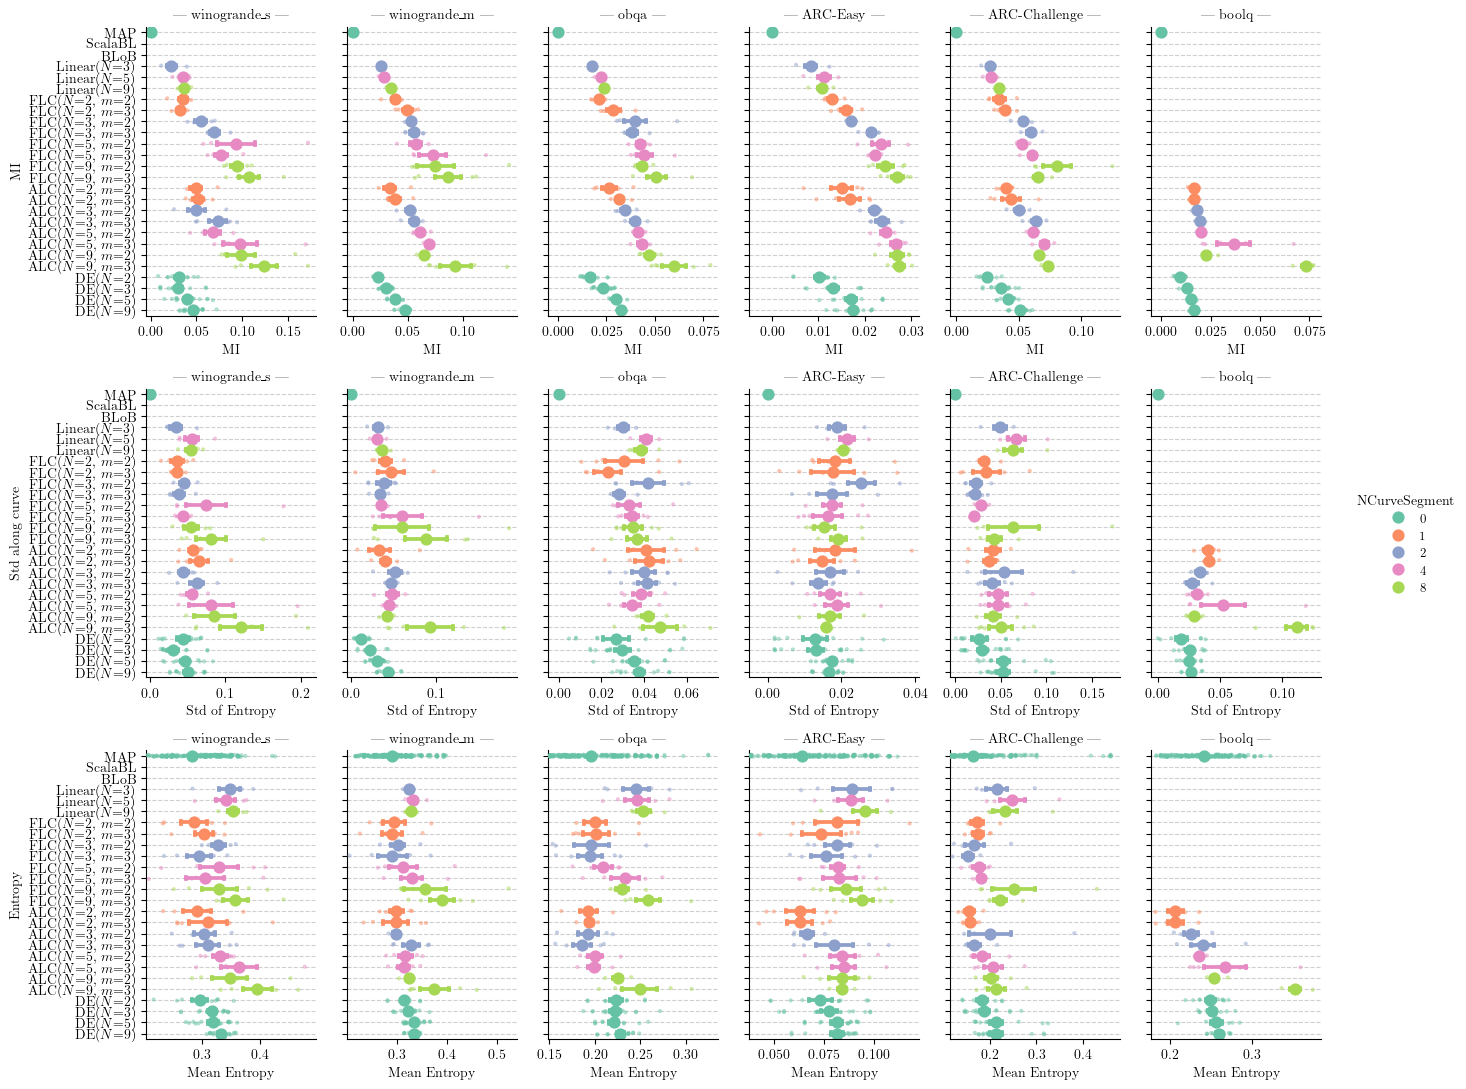

In [71]:
# stack df_vi to df_plot
df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(int(x) for x in df_plot_['NCurveSegment'].unique())
df_plot_['NCurveSegment'] = df_plot_['NCurveSegment'].astype(str)
hue_order = [str(x) for x in numeric_rhos]
colors = plt.get_cmap('plasma', len(hue_order))(np.arange(len(hue_order)))
hue_palette = {n: colors[i] for i, n in enumerate(hue_order)}
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "test_mutual_information_ppd", "test_std_entropy_along_curve", "test_mean_entropy_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = ['MAP', 
         'ScalaBL', 'BLoB', 
         f'Linear({n_seg_name}=3)', f'Linear({n_seg_name}=5)', f'Linear({n_seg_name}=9)', #'OpenLinear(13)',
         rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
         rf'{free_model_name}({n_seg_name}=3, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)', 
         rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
         rf'{free_model_name}({n_seg_name}=9, {seg_deg_name}=3)', 
        #  'Fix=False, N_{n_seg_name}=12, {seg_deg_name}=m$1', 
        #  'Fix=True, N_{n_seg_name}=12, {seg_deg_name}=1', 
        #  'Fix=True, N_{n_seg_name}=2, {seg_deg_name}=1',
         rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=2)', 
         rf'{pretrained_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
         rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
         rf'{pretrained_model_name}({n_seg_name}=3, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
         rf'{pretrained_model_name}({n_seg_name}=9, {seg_deg_name}=3)',
         rf'DE({n_seg_name}=2)', rf'DE({n_seg_name}=3)', rf'DE({n_seg_name}=5)', rf'DE({n_seg_name}=9)'
         ]
print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# Prepare descriptive Model labels
def get_model_label(row):
    if str(row['Model']).startswith('DE'):
        return f"{row['Model']}({row['NCurveSegment']})"
    return f"{row['Model']}"

df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Metric', col='Dataset',
    row_order=col_order, col_order=row_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue='NCurveSegment',
    dodge=False, sharex=False, height=figsize[0]/1.5, aspect=1/1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (metric, ds), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue='NCurveSegment', legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'test_mutual_information_ppd':
        ax.set_xlabel(r'MI')
    elif metric == 'test_std_entropy_along_curve':
        ax.set_xlabel(r'Std of Entropy')
    elif metric == 'test_mean_entropy_ppd':
        ax.set_xlabel(r'Mean Entropy')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
# g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.set_titles(row_template='', col_template='{col_name} |')
g.tight_layout()
g.axes[0,0].set_ylabel('MI')
g.axes[1,0].set_ylabel('Std along curve')
g.axes[2,0].set_ylabel('Entropy')
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/std_mi_along_curve.png", dpi=300)
plt.savefig("result/std_mi_along_curve.pdf", dpi=300)
plt.show()

Models {'Linear($N$=3)', 'Linear($N$=9)', 'Linear($N$=5)'} missing:


/tmp/ipykernel_2061780/446959689.py:28: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


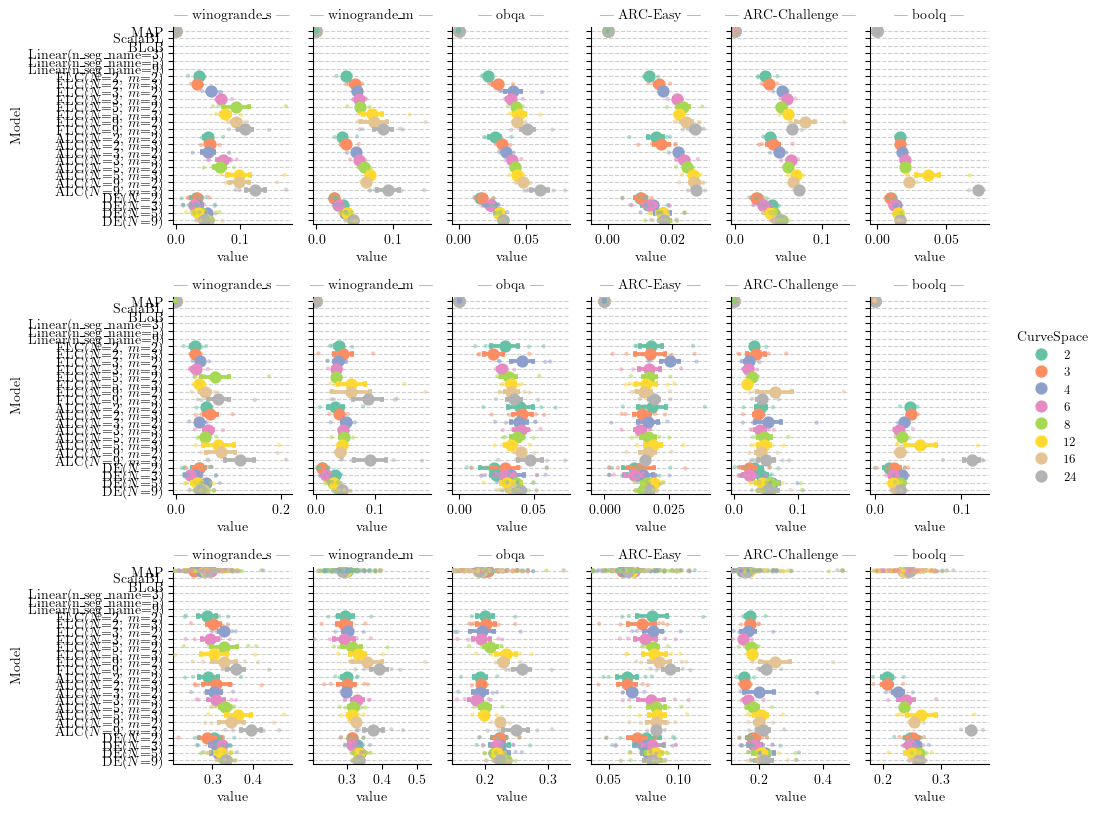

In [70]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
hue_name = 'CurveSpace'
df_plot[hue_name] = df_plot[hue_name].astype(int)
numeric_rhos = sorted(int(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
colors = plt.get_cmap('plasma', len(hue_order))(np.arange(len(hue_order)))
hue_palette = {n: colors[i] for i, n in enumerate(hue_order)}
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# Prepare descriptive Model labels
def get_model_label(row):
    if str(row['Model']).startswith('DE'):
        return f"{row['Model']}({row['NCurveSegment']})"
    return f"{row['Model']}"

df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Metric', col='Dataset',
    row_order=col_order, col_order=row_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=False, sharex=False, height=figsize[0]/2, aspect=1/1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (metric, ds), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=False, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
# g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.set_titles(row_template='', col_template='{col_name} |')
g.tight_layout()
# g.axes[0,0].set_ylabel('MI')
# g.axes[1,0].set_ylabel('Std along curve')
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/std_mi_along_curve.png", dpi=300)
plt.savefig("result/std_mi_along_curve.pdf", dpi=300)
plt.show()

### DE vs Curve

In [73]:
# Build Config label
df_subset = df_clean.copy()
# df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'MAP')]
df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'PPD') & (df_subset['BmaMode'] != 'MAP') & (df_subset['LoraRho'] == 0.25)]

# Filter for only configs with open curves and then inner join back to keep only those configs across all seeds and metrics
match_cols = deepcopy(variable_idx) + ['Seed']
match_cols.remove('NumPretrained')
filter_mask = df_subset[df_subset['NumPretrained'] > 0.][match_cols].drop_duplicates()
df_subset = df_subset.merge(filter_mask, on=match_cols, how='inner')

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)


def map_hue(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = np.sum(x['NumPretrained']) > 0
        seg_deg = x['CurveSegmentDegree']
        curve_space = int(x['CurveSpace'])
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return f"{prefix}({seg_deg_name}={seg_deg})"
    else:
        return "Other"


# df_plot['Model'] = df_plot.apply(map_model, axis=1)
df_plot['Model'] = df_plot.apply(map_hue, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.sort_values(by=['Model'], inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()

df_plot[cols+ ['Model']].apply(np.unique)


Id                    [00oxdnp0, 07jkw5um, 0at7l52y, 0e6rq9pf, 0jjza...
CurveSpace                                  [2, 3, 4, 6, 8, 12, 16, 24]
NumPretrained                                           [0, 2, 3, 5, 9]
Jitter                                                              [0]
Seed                                              [1, 2, 20, 400, 8000]
WeightDecay                                                     [0.001]
Dataset               [ARC-Challenge, ARC-Easy, boolq, obqa, winogra...
BmaMode                                               [DE, PPD Uniform]
DS_Sampling                                                 [minibatch]
DS_Mode                                                       [classic]
DS_WindowSize                                                      [-1]
EntropyMaxScale                                                    [-1]
NumSteps                                                        [10000]
LoraMode                                                    [A(t

In [74]:
df_plot['Model'].unique()

array(['ALC($m$=2)', 'ALC($m$=3)', 'DE', 'FLC($m$=2)', 'FLC($m$=3)',
       'Linear'], dtype=object)

Models set() missing:


/tmp/ipykernel_2061780/707050232.py:31: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


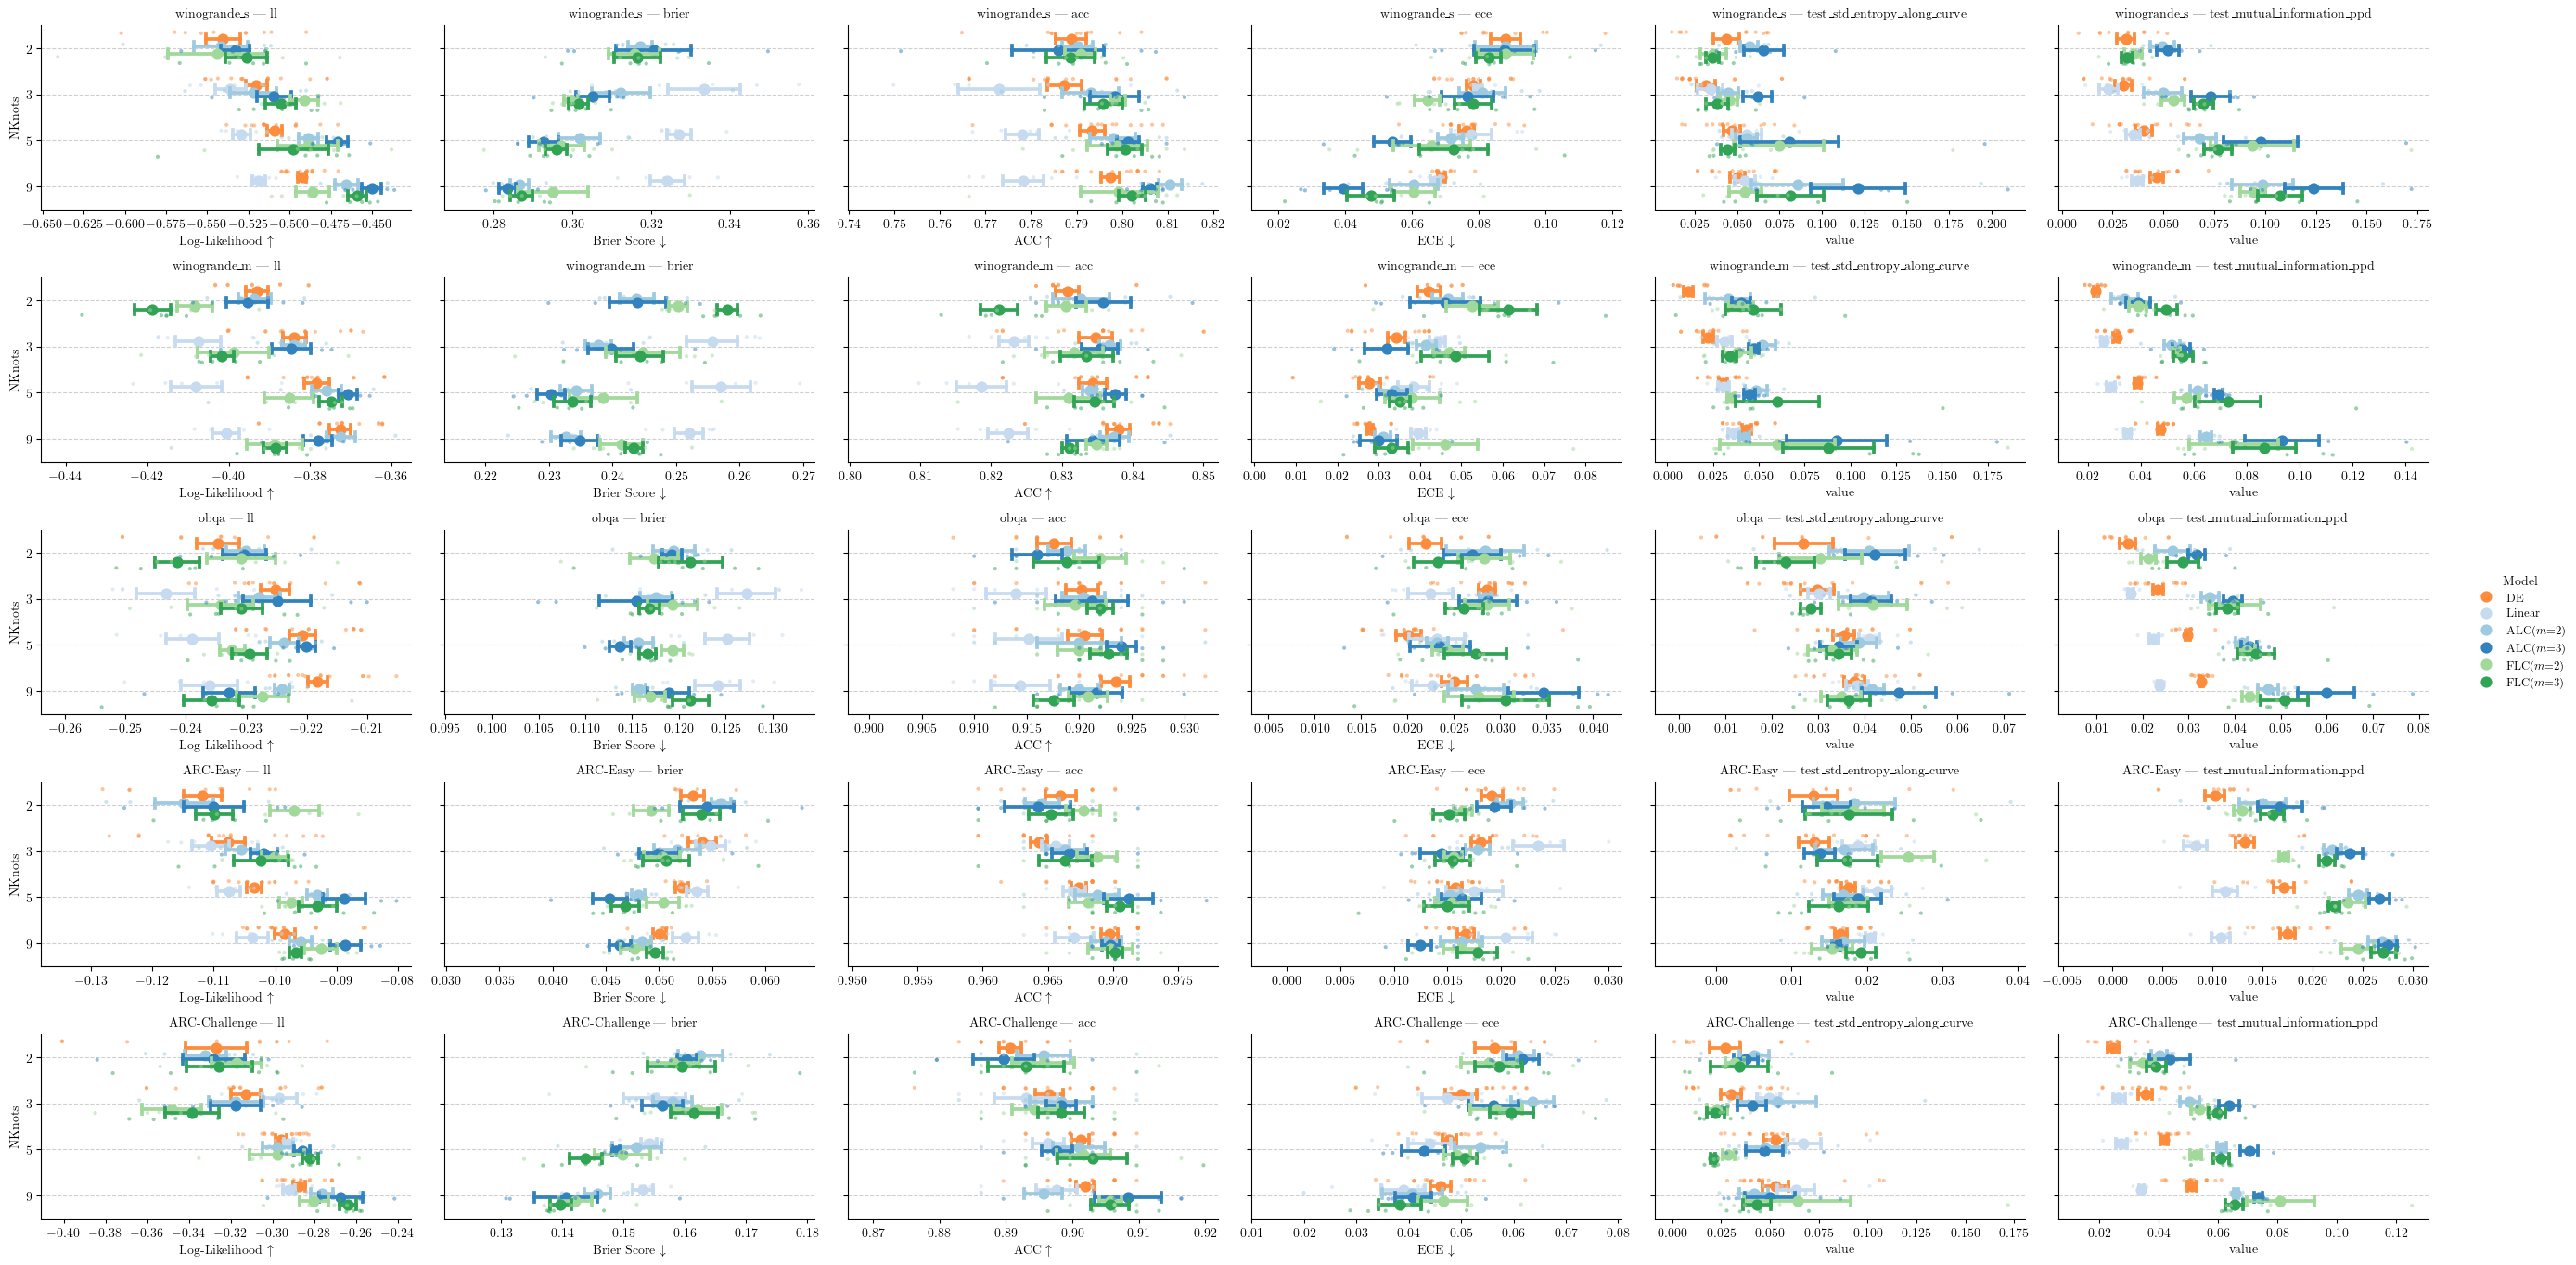

In [83]:
# stack df_vi to df_plot
hue_name = 'Model'
x_name = 'NKnots'
df_plot_ = deepcopy(df_plot)

# hue_order = ['DE', 'Linear', 'Pre(SegDeg=2)', 'Pre(SegDeg=3)', 'AtoCLinear', 'AtoC(SegDeg=2)',  'AtoC(SegDeg=3)']
hue_order = ['DE', 'Linear', f'{pretrained_model_name}({seg_deg_name}=2)', f'{pretrained_model_name}({seg_deg_name}=3)', f'{free_model_name}({seg_deg_name}=2)',  f'{free_model_name}({seg_deg_name}=3)']
hue_palette = sns.color_palette("tab20c")
hue_palette = {'DE': hue_palette[5], 
               'Linear': hue_palette[3], 
               "Linear_" + free_model_name: hue_palette[12], 
               f'{pretrained_model_name}({seg_deg_name}=2)': hue_palette[2], 
               f'{pretrained_model_name}({seg_deg_name}=3)': hue_palette[0], 
               f'{free_model_name}({seg_deg_name}=2)': hue_palette[10],  
               f'{free_model_name}({seg_deg_name}=3)': hue_palette[8]}
col_order = "ll", "brier", "acc", "ece", "test_std_entropy_along_curve", "test_mutual_information_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_[x_name].unique()
order.sort()
# order = ['MAP', 'DE(5)', 'Fix=False, N_Seg=1, SegDeg=2',
#        'Fix=False, N_Seg=3, SegDeg=2', 'Fix=False, N_Seg=6, SegDeg=2',
#        'Fix=True, N_Seg=4, SegDeg=3']


print(f"Models {set(df_plot_[x_name].unique()) - set(order)} missing:")
# x as string for catplot
df_plot_[x_name] = df_plot_[x_name].astype(str)
order = [str(x) for x in order]

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y=x_name,
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset[x_name] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset[x_name] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.01)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

/tmp/ipykernel_2061780/3066841950.py:6: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


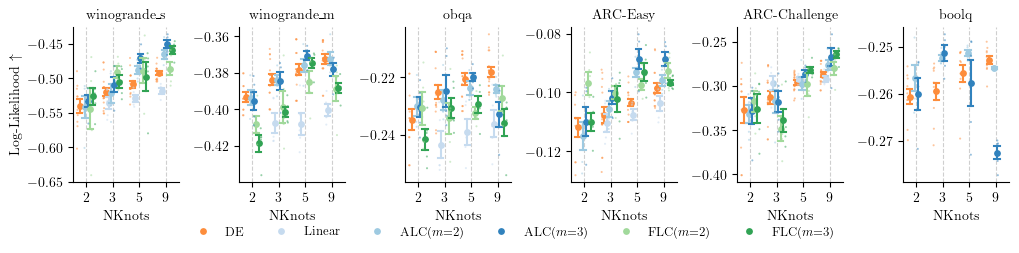

In [84]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]

g = sns.catplot(
    data=df_plot_ll, y='value', x=x_name,
    col='Dataset', col_wrap=6,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2, linewidth=1.5,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.5, sharey=False, sharex=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, y='value', x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.5, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # # Label mapping for x-axis
    ax.set_ylabel('')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset[x_name] != 'MAP']['value'])
    map_vals = only_finit(subset[subset[x_name] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    
    # if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
    #     ax.set_ylim(min(min_value, mean_value_MAP)-0.01)  # add some padding on the left
    # elif np.isfinite(min_value):
    #     ax.set_ylim(min_value-0.01)

g.axes[0].set_ylabel(r'Log-Likelihood $\uparrow$')
# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

# sns.move_legend(g, loc='center', bbox_to_anchor=(0.83, 0.25), title=hue_name)
# flatten legend at top
sns.move_legend(g, loc='lower center', bbox_to_anchor=(0.45, -0.05), ncol=len(hue_order), title="")

plt.savefig("result/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.show()

/tmp/ipykernel_2061780/602413059.py:7: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


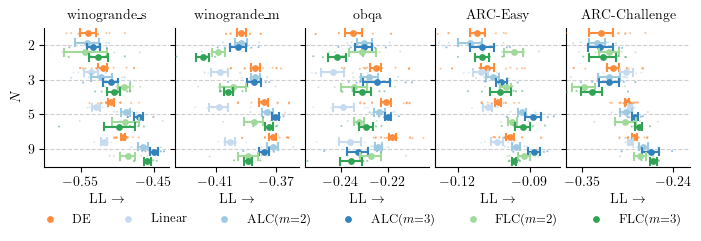

In [94]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]

g = sns.catplot(
    data=df_plot_ll, x='value', y=x_name,
    col='Dataset', col_wrap=6,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2, linewidth=1.5,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.7, sharex=False, height=figsize[1]/1.5, aspect=1/1.6,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='value', y=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # # Label mapping for x-axis
    # ax.set_ylabel('')
    ax.set_xlabel(r'LL $\rightarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset[x_name] != 'MAP']['value'])
    map_vals = only_finit(subset[subset[x_name] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_xlim(min(min_value, mean_value_MAP)-0.001)  # add some padding on the left
    elif np.isfinite(min_value):
        ax.set_xlim(min_value-0.001)

# g.axes[0].set_xlabel(r'Log-Likelihood $\rightarrow$')
# Adjust layout and titles
g.set_titles(col_template='{col_name}')
# reduce vertical space between subplots
g.tight_layout()
g.fig.subplots_adjust(wspace=0.05)

# sns.move_legend(g, loc='center', bbox_to_anchor=(0.83, 0.25), title=hue_name)
# flatten legend at top
sns.move_legend(g, loc='lower center', bbox_to_anchor=(0.38, -0.07), ncol=len(hue_order), title="")
g.axes[0].set_xlim(-0.6, -0.43)
g.axes[4].set_xlim(-0.37, -0.22)
g.axes[0].set_xticks([-0.55, -0.45])
g.axes[1].set_xticks([-0.41, -0.37])
g.axes[2].set_xticks([-0.24, -0.22])
g.axes[3].set_xticks([-0.12, -0.09])
g.axes[4].set_xticks([-0.35, -0.24])
# g.axes[5].set_xticks([-0.27, -0.25])
g.set_ylabels(n_seg_name)

plt.savefig("result/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/figures/performance_DE_vs_Curve.pdf", dpi=300, bbox_inches='tight')
plt.show()

In [41]:
df_check = df_plot[df_plot['Metric'] == 'll'].groupby(['NCurveSegment', 'Model', 'Dataset'])[cols].agg(lambda x: len(np.unique(x).tolist()))
# drop columns with only 1 as value
cols_to_drop = [c for c in cols if df_check[c].max() <= 1]
print(f"Dropping columns with only 1 unique value across seeds: {cols_to_drop}")
df_check = df_check.drop(columns=cols_to_drop)
df_check

Dropping columns with only 1 unique value across seeds: ['NumPretrained', 'Jitter', 'WeightDecay', 'Dataset', 'BmaMode', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'EntropyMaxScale', 'NumSteps', 'LoraMode', 'CurveMode', 'LoraRank', 'RegularizationMode', 'Gravity', 'EnergyWeakening', 'Tsample', 'LoraRho', 'LoraRhoS', 'RhoFrequency', 'NCurveSegment', 'OpenEndSegment']


Id  CurveSpace  Seed  \
NCurveSegment Model         Dataset                               
1             DE            ARC-Challenge  10           2     5   
                            ARC-Easy       10           2     5   
                            boolq          10           2     5   
                            obqa           10           2     5   
                            winogrande_m   10           2     5   
...                                        ..         ...   ...   
8             Pre(SegDeg=3) ARC-Easy        5           1     5   
                            boolq           5           1     5   
                            obqa            5           1     5   
                            winogrande_m    5           1     5   
                            winogrande_s    5           1     5   

                                           CurveSegmentDegree  
NCurveSegment Model         Dataset                            
1             DE            ARC-Challenge                   2  
                            ARC-Easy                        2  
                            boolq                           2  
                            obqa                            2  
                            winogrande_m                    2  
...                                                       ...  
8             Pre(SegDeg=3) ARC-Easy                        1  
                            boolq                           1  
                            obqa                            1  
                            winogrande_m                    1  
                            winogrande_s                    1  

[127 rows x 4 columns]

In [42]:
df_plot[df_plot['Metric'] == 'll'].groupby(['NCurveSegment', 'Model', 'Dataset'])[cols].agg(lambda x: np.unique(x).tolist()).drop(columns=cols_to_drop)

Id  \
NCurveSegment Model         Dataset                                                            
1             DE            ARC-Challenge  [5lnmi732, c1dl05km, cqgb3wrr, g67o1gt8, i8x6w...   
                            ARC-Easy       [0z4wnjng, 4jrewnfa, 6780bwk2, 6c5rgqb4, f8tmz...   
                            boolq          [2hva45q6, 5zpnp6fe, 7773ro6v, bfu0wk5u, mippj...   
                            obqa           [0e6rq9pf, 2ob26p6i, dvvyqw05, hemr9p3g, hmxsf...   
                            winogrande_m   [1795x1mv, 32cyg0ui, 3dni495n, 8hw70we6, im16q...   
...                                                                                      ...   
8             Pre(SegDeg=3) ARC-Easy       [0sttm8qr, ba9ox4nx, d5b1doju, j90bgqsd, uakgp...   
                            boolq          2hztdy, gukgr58t, ksxw8pf4, o83hf81q, tgr58...   
                            obqa           [64rd54g0, 6bqx5tze, 70kj9zy7, sg3whxxv, uovw2...   
                            winogrande_m   [2ux865zd, 4cpojngq, 4wtppnwq, oa90hzt3, zg740...   
                            winogrande_s   [8nrd2257, bkm5r7pd, gw9aaaeu, ndodzfmf, re5dq...   

                                          CurveSpace                   Seed  \
NCurveSegment Model         Dataset                                           
1             DE            ARC-Challenge     [2, 3]  [1, 2, 20, 400, 8000]   
                            ARC-Easy          [2, 3]  [1, 2, 20, 400, 8000]   
                            boolq             [2, 3]  [1, 2, 20, 400, 8000]   
                            obqa              [2, 3]  [1, 2, 20, 400, 8000]   
                            winogrande_m      [2, 3]  [1, 2, 20, 400, 8000]   
...                                              ...                    ...   
8             Pre(SegDeg=3) ARC-Easy            [24]  [1, 2, 20, 400, 8000]   
                            boolq               [24]  [1, 2, 20, 400, 8000]   
                            obqa                [24]  [1, 2, 20, 400, 8000]   
                            winogrande_m        [24]  [1, 2, 20, 400, 8000]   
                            winogrande_s        [24]  [1, 2, 20, 400, 8000]   

                                          CurveSegmentDegree  
NCurveSegment Model         Dataset                           
1             DE            ARC-Challenge             [2, 3]  
                            ARC-Easy                  [2, 3]  
                            boolq                     [2, 3]  
                            obqa                      [2, 3]  
                            winogrande_m              [2, 3]  
...                                                      ...  
8             Pre(SegDeg=3) ARC-Easy                     [3]  
                            boolq                        [3]  
                            obqa                         [3]  
                            winogrande_m                 [3]  
                            winogrande_s                 [3]  

[127 rows x 4 columns]

In [43]:
# check similar DE runs (should have the same values for same seed)
# small differences are okay due to different Hardware and non-determinism, but large differences may indicate a problem
df_check = df_plot[(df_plot['Model'] == 'DE') & (df_plot['Metric'] == 'll') & (df_plot['NCurveSegment'] == 2)].groupby(['NCurveSegment', 'Model', 'Dataset', 'Metric', 'Seed'])['value'].describe()
df_check[df_check['count'] > 1]

count      mean       std  \
NCurveSegment Model Dataset       Metric Seed                              
2             DE    ARC-Challenge ll     1       3.0 -0.282325  0.010064   
                                         2       3.0 -0.347240  0.022903   
                                         20      3.0 -0.318867  0.000124   
                                         400     3.0 -0.325780  0.017803   
                                         8000    3.0 -0.290094  0.010586   
                    ARC-Easy      ll     1       3.0 -0.100864  0.007281   
                                         2       3.0 -0.123852  0.002788   
                                         20      3.0 -0.110870  0.000000   
                                         400     3.0 -0.102586  0.008047   
                                         8000    3.0 -0.100226  0.008081   
                    boolq         ll     1       2.0 -0.261266  0.002462   
                                         2       2.0 -0.255579  0.002853   
                                         20      2.0 -0.256816  0.002437   
                                         400     2.0 -0.269186  0.002489   
                                         8000    2.0 -0.254520  0.000175   
                    obqa          ll     1       3.0 -0.227300  0.004035   
                                         2       3.0 -0.232889  0.005749   
                                         20      3.0 -0.211230  0.000076   
                                         400     3.0 -0.225662  0.000407   
                                         8000    3.0 -0.229063  0.011008   
                    winogrande_m  ll     1       3.0 -0.389579  0.002391   
                                         2       3.0 -0.390984  0.015952   
                                         20      3.0 -0.368989  0.001694   
                                         400     3.0 -0.388635  0.010664   
                                         8000    3.0 -0.381198  0.000000   
                    winogrande_s  ll     1       3.0 -0.548660  0.004414   
                                         2       3.0 -0.486602  0.016188   
                                         20      3.0 -0.513203  0.000000   
                                         400     3.0 -0.537503  0.009313   
                                         8000    3.0 -0.514986  0.023723   

                                                    min       25%       50%  \
NCurveSegment Model Dataset       Metric Seed                                 
2             DE    ARC-Challenge ll     1    -0.293945 -0.285230 -0.276514   
                                         2    -0.360463 -0.360463 -0.360463   
                                         20   -0.318939 -0.318939 -0.318939   
                                         400  -0.346338 -0.330975 -0.315612   
                                         8000 -0.296206 -0.296206 -0.296206   
                    ARC-Easy      ll     1    -0.109122 -0.103614 -0.098106   
                                         2    -0.127071 -0.124656 -0.122242   
                                         20   -0.110870 -0.110870 -0.110870   
                                         400  -0.107232 -0.107232 -0.107232   
                                         8000 -0.108394 -0.104221 -0.100048   
                    boolq         ll     1    -0.263007 -0.262136 -0.261266   
                                         2    -0.257596 -0.256587 -0.255579   
                                         20   -0.258539 -0.257678 -0.256816   
                                         400  -0.270945 -0.270065 -0.269186   
                                         8000 -0.254644 -0.254582 -0.254520   
                    obqa          ll     1    -0.229630 -0.229630 -0.229630   
                                         2    -0.239478 -0.234886 -0.230294   
                                         20   -0.211274 -0.211274 -0.211274   
                                  

### Per Leave sampling

In [4]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in ["fns49u4k", "i9dggv82"]:
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_test/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        if mp.get('curve_segment', False) == False:
            NCurveSegment = 1
            CurveDegree = len(mp['cp_fix']) - 1
        else:
            NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
            CurveDegree = mp['curve_segment']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            CurveSpace=len(mp['cp_fix']),
            CpFix=str(mp['cp_fix']),
            NumPretrained=np.sum(mp['cp_fix']),
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if np.sum(mp['cp_fix']) > 0:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
            results.append(_res)
            for i, fix in enumerate(mp['cp_fix']):
                if fix != False:
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

df = pd.DataFrame(results)
filter_list = {'CpFix': df['CpFix'].unique(), 
               'CuveSegmentDegree': df['CurveSegmentDegree'].unique(),
               'lora_rho': df['LoraRho'].unique(),
               'lora_mode': df['LoraMode'].unique(),}

results = []
t_run = tqdm(api.runs(f"ddold/qwen_PtoC_seg"))
for run in t_run:
    if run.state != 'finished' or not hasattr(run, "config") or run.sweep is None:
        # print(f"Skipping {run.name} because it is not finished")
        continue
    mp = run.config['model_params']
    opt_conf = run.config['optimizer_conf']
    hp = run.config['train_hyper']
    lora = mp['lora_params']

    if mp.get('curve_segment', False) == False:
        NCurveSegment = 1
        CurveDegree = len(mp['cp_fix']) - 1
    else:
        NCurveSegment=(len(mp['cp_fix']) - 1) // mp['curve_segment']
        CurveDegree = mp['curve_segment']

    if not (str(mp['cp_fix']) in filter_list['CpFix'] 
            and CurveDegree in filter_list['CuveSegmentDegree']
            and lora.get('lora_rho', -1) in filter_list['lora_rho']
            and lora.get('lora_mode', 'None') in filter_list['lora_mode']):
        continue
    t_run.set_postfix_str(f"Processing {run.name}")
    res = dict(Id=run.id,
    #    CurveSpace=f"{mp['k']}",
        CurveSpace=len(mp['cp_fix']),
        CpFix=str(mp['cp_fix']),
        NumPretrained=np.sum(mp['cp_fix']),
        Jitter=mp['jitter_multiplier'],
        Seed=run.config['rng_seed'],
        WeightDecay=opt_conf['kwargs']['weight_decay'],
        Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
        BmaMode="PPD",
        DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
        DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
        DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
        EntropyMaxScale=mp.get('entropy_maxim', -1),
        NumSteps=hp.get('num_steps', -1),
        LoraMode=lora.get('lora_mode', 'None'),
        CurveMode=mp.get('curve_parameterization', 'Bezier'),
        LoraRank=lora.get('r', -1),
        RegularizationMode=mp.get('regularizer', False),
        Gravity=mp.get('gravity', 0.),
        EnergyWeakening=mp.get('energy_weakening', 0.),
        Tsample=mp.get('curve_sampling_mode', 'None'),
        LoraRho=lora.get('lora_rho', -1),
        LoraRhoS=lora.get('lora_rho_s', -1),
        RhoFrequency=lora.get('rho_scheduler_frequency', 0),
        CurveSegmentDegree=CurveDegree,
        NCurveSegment=NCurveSegment,
        OpenEndSegment=mp.get('independent_connected', False),
        bezierLength=run.summary.get('Curve length', 0),
        acc=run.summary.get(f"test_ppd_acc", -np.inf),
        ece=run.summary.get(f"test_ppd_ece", -np.inf),
        ll=run.summary.get(f"test_ppd_ll", -np.inf),
        test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
        test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
        test_std_entropy_along_curve=0,
        test_mean_entropy_along_curve=0,
        )
    results.append(res)
    # add DE   
    _res = deepcopy(res)
    _res['BmaMode'] = "DE"
    _res['acc'] = run.summary.get(f"DE_acc", -np.inf)
    _res['ece'] = run.summary.get(f"DE_ece", -np.inf)
    _res['ll'] = run.summary.get(f"DE_ll", -np.inf)
    results.append(_res)
    for i, fix in enumerate(mp['cp_fix']):
        if fix != False:
            _res = deepcopy(res)
            _res['BmaMode'] = "MAP"
            # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
            _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
            _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
            _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
            # print(_res['acc'], _res['ece'], _res['ll'])
            results.append(_res)

    # add PPD uniform   
    _res = deepcopy(res)
    _res['BmaMode'] = "PPD Uniform"
    _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
    _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
    _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)

    _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
    _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
    _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
    _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
    results.append(_res)

df2 = pd.DataFrame(results)
df = pd.concat([df, df2], ignore_index=True)
df.describe().T

fns49u4k:   0%|          | 0/60 [00:00<?, ?it/s, fresh-sweep-31]      

i9dggv82:  33%|███▎      | 21/64 [00:00<00:00, 143.23it/s, devoted-sweep-25]      

Skipping comfy-sweep-64 because it is not finished
Skipping valiant-sweep-63 because it is not finished


100%|██████████| 793/793 [00:01<00:00, 487.34it/s, Processing denim-sweep-39]         
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered

,count,mean,std,min,25%,50%,75%,max
CurveSpace,604.0,1.300000e+01,0.000000e+00,1.300000e+01,13.000000,13.000000,13.000000,13.000000
NumPretrained,604.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,604.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,604.0,1.021706e+04,1.943930e+04,1.000000e+00,2.000000,20.000000,16000.000000,64000.000000
WeightDecay,604.0,1.000000e-03,2.170202e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,604.0,-5.033113e-01,1.496814e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,4.000000
EntropyMaxScale,604.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,604.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,604.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,604.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [5]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [13]
CpFix ['[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]']
NumPretrained [0]
Jitter [0]
Seed [   20     2     1   400  8000    40   800 16000 32000 64000]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'obqa' 'winogrande_m' 'winogrande_s' 'boolq']
BmaMode ['PPD' 'PPD Uniform' 'DE']
DS_Sampling ['minibatch' 'expert']
DS_Mode ['classic' 'Random']
DS_WindowSize [-1  4]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['per_leave' 'combined_all']
LoraRho [0.25 0.1  0.  ]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [2 3]
NCurveSegment [6 4]
OpenEndSegment [False]

Experiment differs in ['Dataset', 'BmaMode', 'DS_Sampling', 'DS_Mode', 'DS_WindowSize', 'Tsample', 'LoraRho', 'CurveSegmentDegree', 'NCurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [6]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


# drop LoraMode that is not "A(t)eB(t)"
df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_merge(x):
    res = f"{x['DS_Sampling']} | \#Seg={x['NCurveSegment']}, SegDeg={x['CurveSegmentDegree']}, rho={x['LoraRho']}"    
    return res

df_plot['Model'] = df_plot.apply(map_merge, axis=1)
df_plot.sort_values(by=['Model'], inplace=True)


Models set() missing:


/tmp/ipykernel_1476607/2648328022.py:17: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


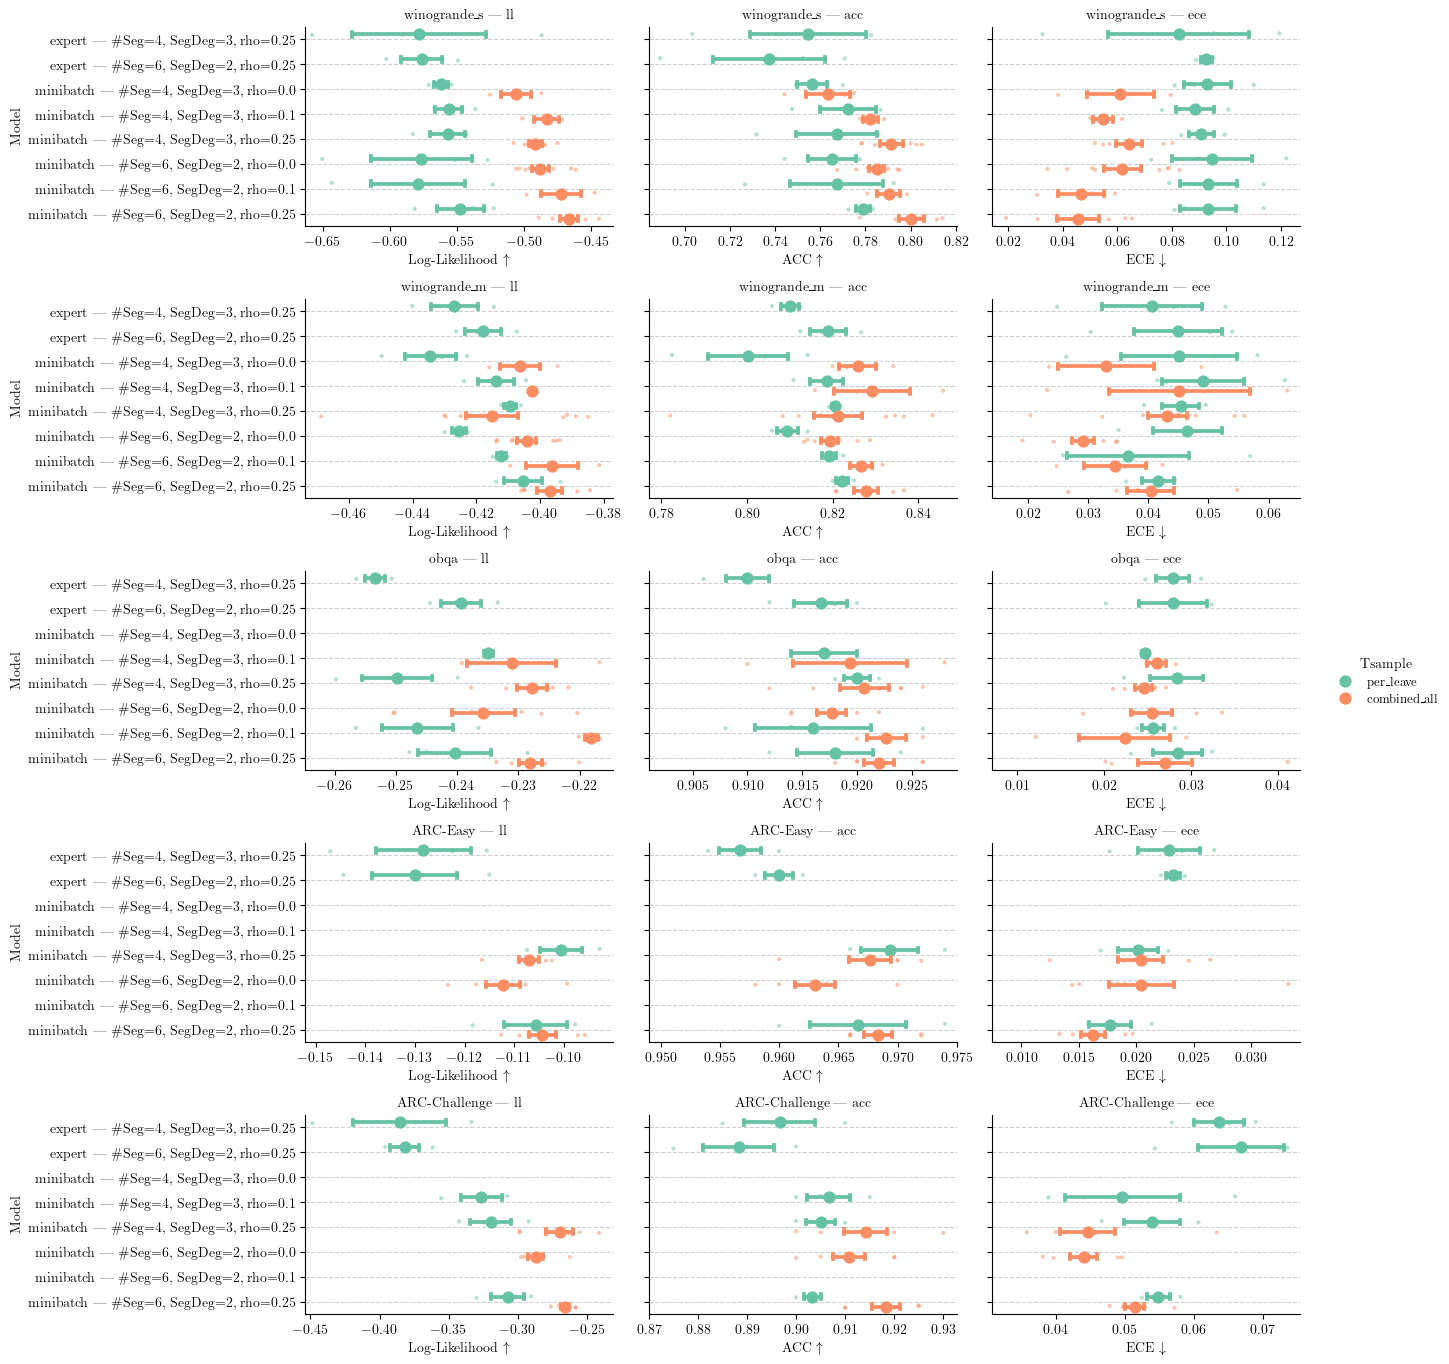

In [8]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
# remove duplicates
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()

# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()
order.sort()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

In [142]:
# filter out only similar seed runs
df_plot_.groupby(variable_idx)['Seed'].unique()

Dataset        BmaMode      DS_Sampling  DS_Mode  DS_WindowSize  Tsample       CurveSegmentDegree  NCurveSegment
ARC-Challenge  PPD Uniform  expert       Random    4             per_leave     2                   6                                                       [1, 2, 20]
                                                                               3                   4                                                       [1, 2, 20]
                            minibatch    classic  -1             combined_all  2                   6                                [2, 40, 800, 16000, 32000, 64000]
                                                                               3                   4                                [2, 40, 800, 16000, 32000, 64000]
                                                                 per_leave     2                   6                                                       [1, 2, 20]
                                                         

Models set() missing:


/tmp/ipykernel_888869/2605597187.py:17: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


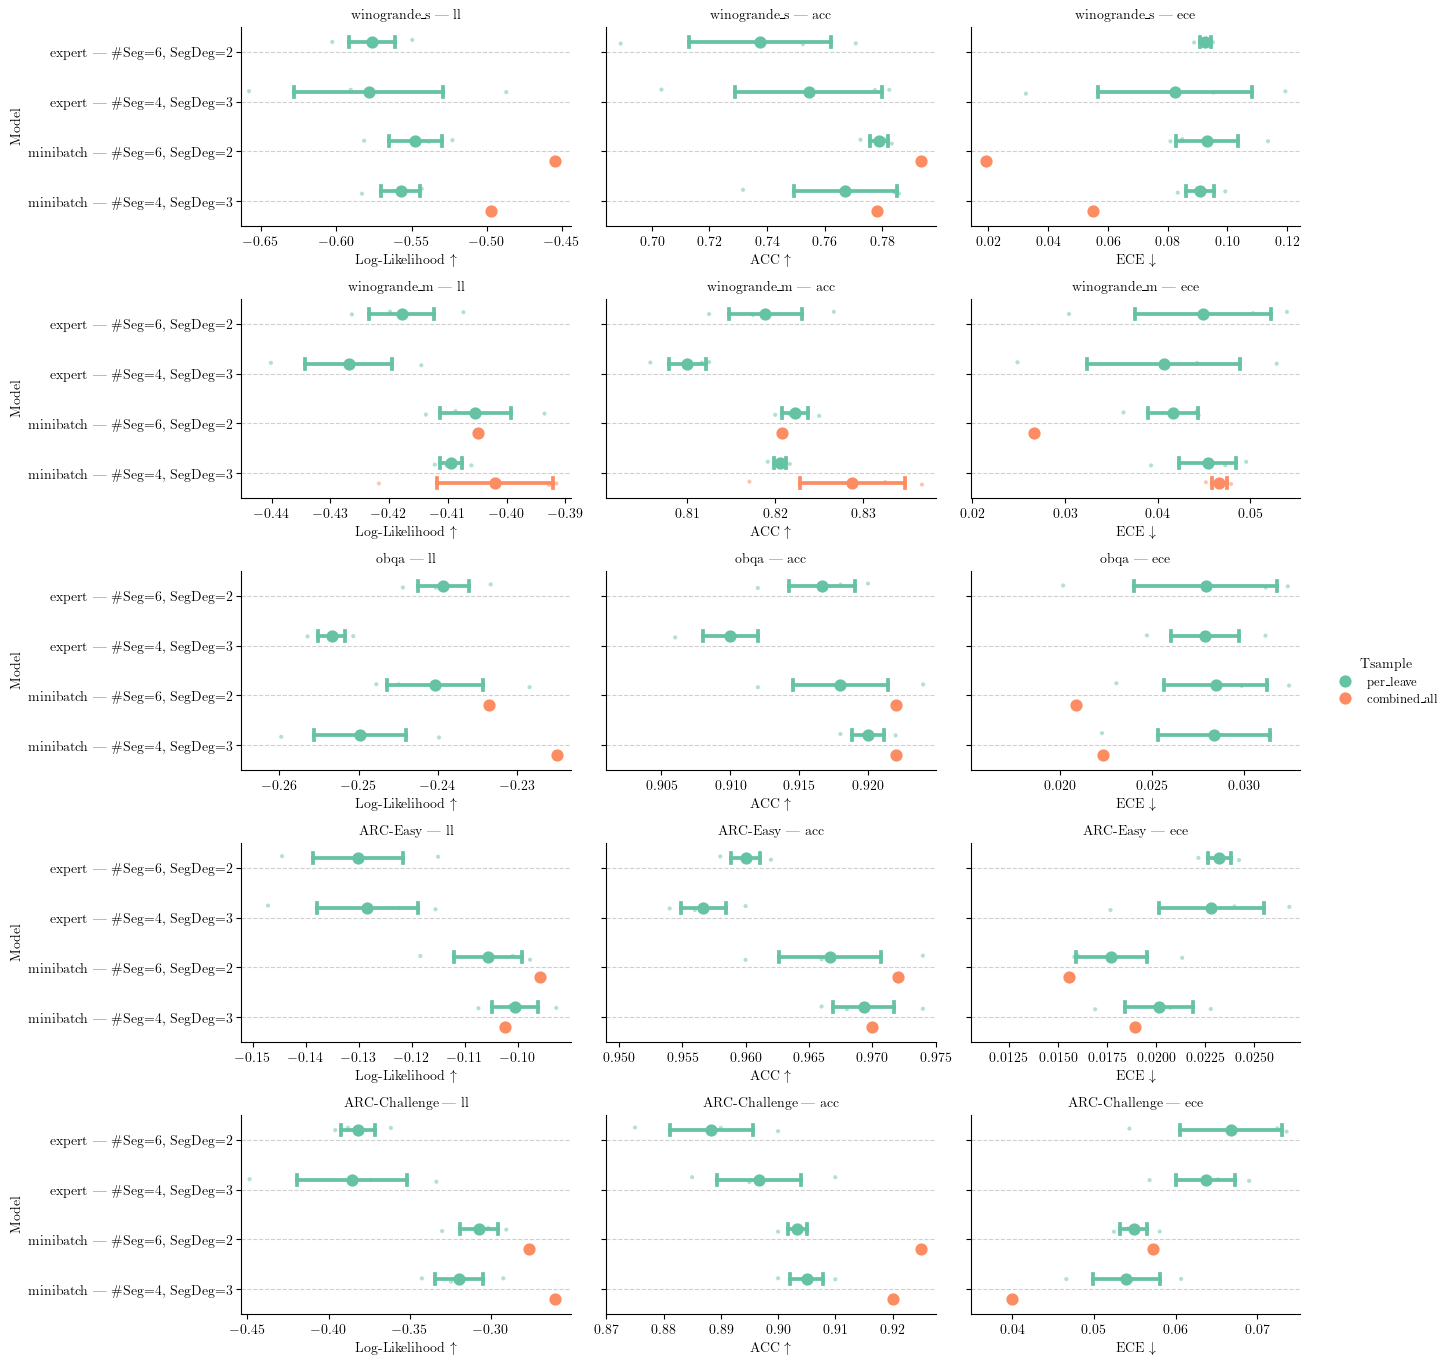

In [146]:
# stack df_vi to df_plot
df_plot_ = pd.concat([df_plot,], ignore_index=True)
df_plot_ = df_plot_.groupby(variable_idx+['Model', 'Seed', 'Metric'])['value'].mean().reset_index()
df_plot_ = df_plot_[df_plot_['Seed'].isin([1,2,20])]


# hue
hue_name = 'Tsample'
hue_order = df_plot_[hue_name].unique()
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", ) # hue_order=hue_order,)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

### table

In [33]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'we8wq8n7', 'solftkne', 'kru2lo9d', '5wyd4ltr']): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            ModelMode=mp.get('subspace_model', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

w0kaq8i0: 100%|██████████| 200/200 [00:00<00:00, 325.55it/s, colorful-sweep-6]      
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,3310.0,9.894260e+00,7.172127e+00,2.000000e+00,4.000000,8.000000,16.000000,24.000000
NumPretrained,3310.0,4.444109e+00,3.478430e+00,0.000000e+00,2.000000,5.000000,9.000000,9.000000
Jitter,3310.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,3310.0,1.684600e+03,3.161839e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,3310.0,1.000000e-03,4.337464e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,3310.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,3310.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,3310.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,3310.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,3310.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [34]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [24 12  6  3 16  8  4  2]
NumPretrained [0 9 5 3 2]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'obqa' 'ARC-Challenge' 'winogrande_s' 'winogrande_m' 'boolq']
BmaMode ['PPD' 'PPD Uniform' 'DE' 'MAP']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2 1]
NCurveSegment [8 4 2 1]
OpenEndSegment [False]
ModelMode ['jsd_v2_category' 'lora_category']

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'ModelMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'boolq', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [35]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode']]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]


def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_AtoC"
            return f"{prefix}({x['NumPretrained']})"
        else:
            prefix = "EtoC" if is_fixed else "AtoC"
            name = f"{prefix}({n_seg_name}={x['NCurveSegment']}, {seg_deg_name}={seg_deg})"
            if x['ModelMode'] != "lora_category":
                name += f"+JSD"
            return name
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot = pd.concat([df_plot, df_vi, df_sampling], ignore_index=True)
df_plot.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [36]:
df_plot['Model'].unique()

array(['AtoC($N_{\\mathrm{seg}}$=1, $m$=2)',
       'AtoC($N_{\\mathrm{seg}}$=1, $m$=2)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=1, $m$=3)',
       'AtoC($N_{\\mathrm{seg}}$=1, $m$=3)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=2, $m$=2)',
       'AtoC($N_{\\mathrm{seg}}$=2, $m$=2)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=2, $m$=3)',
       'AtoC($N_{\\mathrm{seg}}$=2, $m$=3)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=4, $m$=2)',
       'AtoC($N_{\\mathrm{seg}}$=4, $m$=2)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=4, $m$=3)',
       'AtoC($N_{\\mathrm{seg}}$=4, $m$=3)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=8, $m$=2)',
       'AtoC($N_{\\mathrm{seg}}$=8, $m$=2)+JSD',
       'AtoC($N_{\\mathrm{seg}}$=8, $m$=3)',
       'AtoC($N_{\\mathrm{seg}}$=8, $m$=3)+JSD', 'BLoB', 'DE(2)', 'DE(3)',
       'DE(5)', 'DE(9)', 'EtoC($N_{\\mathrm{seg}}$=1, $m$=2)',
       'EtoC($N_{\\mathrm{seg}}$=1, $m$=3)',
       'EtoC($N_{\\mathrm{seg}}$=2, $m$=2)',
       'EtoC($N_{\\mathrm{seg}}$=2, $m$=3)',
       'EtoC($N_{\\mathr

In [37]:
# Generate updated LaTeX table from the latest merged dataframe (df_plot)
from pathlib import Path
import numpy as np
import pandas as pd

if "df_plot" not in globals():
    raise RuntimeError("df_plot not found. Run the merge cell (sampling_scalabl_merge_01) first.")

datasets = ["ARC-Challenge", "ARC-Easy", "obqa", "winogrande_m", "winogrande_s"]
metrics = ["acc", "ece", "ll"]
model_order = ['MAP', 
               'BLoB', 'ScalaBL',
               'Linear(3)', 
               'DE(3)', 'DE(9)', 
            #    '$\\bigcirc$Curve(\\#1, {seg_deg_name}2)', '$\\bigcirc$Curve(\\#1, {seg_deg_name}2)+JSD', '$\\triangle$Curve(\\#1, {seg_deg_name}2)',
               f'EtoC({n_seg_name}=1, {seg_deg_name}=2)',
               f'AtoC({n_seg_name}=8, {seg_deg_name}=3)', f'EtoC({n_seg_name}=8, {seg_deg_name}=3)',
               'Sampling-PSMILE'
]

df_tbl = df_plot.copy()
df_tbl = df_tbl[df_tbl["Metric"].isin(metrics) & df_tbl["Dataset"].isin(datasets)].copy()
df_tbl = df_tbl[df_tbl["Model"].isin(model_order)]
df_tbl = df_tbl[np.isfinite(df_tbl["value"])]
df_tbl.loc[(df_tbl["Model"] == "Sampling-PSMILE") & (df_tbl["Metric"] == "ece"), 'value'] = np.inf

grp = df_tbl.groupby(["Metric", "Model", "Dataset"])["value"]
mean = grp.mean()
std2 = 2 * grp.std()

def fmt_plain(m, s):
    if pd.isna(m) or not np.isfinite(m):
        return "-"
    if pd.isna(s):
        return f"{m:.3f}"
    return f"{m:.3f} $\\pm$ {s:.3f}"

def is_better(metric, candidate, current):
    if pd.isna(current):
        return True
    if metric == "ece":
        return candidate < current
    return candidate > current

best_map = {}
for metric in metrics:
    for ds in datasets:
        best_val = np.nan
        for model in model_order:
            v = mean.get((metric, model, ds), np.nan)
            if pd.isna(v) or not np.isfinite(v):
                continue
            if is_better(metric, v, best_val):
                best_val = v
        best_map[(metric, ds)] = best_val

def mark_text(metric, model, ds):
    m = mean.get((metric, model, ds), np.nan)
    s = std2.get((metric, model, ds), np.nan)
    text = fmt_plain(m, s)
    if text == "-":
        return text

    best_val = best_map.get((metric, ds), np.nan)
    if pd.isna(best_val):
        return text

    if np.isclose(m, best_val, rtol=1e-12, atol=1e-12):
        # return f"\\textbf{{\\underline{{{text}}}}}"
        return f"\\textbf{{{text}}}"

    low = m - s if pd.notna(s) else m
    high = m + s if pd.notna(s) else m
    if low <= best_val <= high:
        return f"\\underline{{{text}}}"
    return text

rows = []
for metric in metrics:
    for model in model_order:
        row = {"Metric": metric, "Model": model}
        any_present = False
        for ds in datasets:
            plain = fmt_plain(mean.get((metric, model, ds), np.nan), std2.get((metric, model, ds), np.nan))
            row[ds] = mark_text(metric, model, ds)
            if plain != "-":
                any_present = True
        if any_present:
            rows.append(row)

df_table = pd.DataFrame(rows)
out_csv = "result/performance_table.csv"
df_table.to_csv(out_csv, index=False)

# Build LaTeX table block
def esc(s):
    s = str(s)
    if not '$' in s:
        s = s.replace("_", "\\_")
    s = s.replace("&", "\\&")
    s = s.replace("%", "\\%")
    return s

def name_metric(m):
    if m == "acc":
        return "ACC $\\uparrow$"
    elif m == "ece":
        return "ECE $\\downarrow$"
    elif m == "ll":
        return "LL $\\uparrow$"
    else:
        return esc(m)

lines = []
lines.append("\\begin{table*}[htbp]")
lines.append("\\centering")
lines.append("\\caption{Comparison of MAP, VI, DE, Linear Mode connection, Curve, and MCMC methods on the different datasets. The performance table shows the mean $\\pm$ 2$\\sigma$ across available seeds. Best metric per dataset is bolded; models whose mean$\\pm$2$\\sigma$ interval contains the best are underlined.}")
lines.append("\\label{tab:performance_metrics_updated}")
lines.append("\\resizebox{\\textwidth}{!}{%")
lines.append("\\begin{tabular}{llccccc}")
lines.append("\\toprule")
lines.append("\\textbf{Metric} & \\textbf{Model} & \\textbf{ARC-Challenge} & \\textbf{ARC-Easy} & \\textbf{obqa} & \\textbf{winogrande\\_m} & \\textbf{winogrande\\_s} " + r"\\")
lines.append("\\midrule")

# Calculate row counts for each metric to use with \multirow
metric_counts = df_table["Metric"].value_counts()
seen_metrics = set()

for i, r in df_table.iterrows():
    metric = r["Metric"]
    
    # Add midrule between different metrics
    if i > 0 and metric != df_table.iloc[i - 1]["Metric"]:
        lines.append("\\midrule")
        
    # Group the Metric column using \multirow
    if metric not in seen_metrics:
        count = metric_counts[metric]
        metric_str = f"\\multirow{{{count}}}{{*}}{{{name_metric(metric)}}}"
        seen_metrics.add(metric)
    else:
        metric_str = "" # Leave blank for subsequent rows in the same group

    lines.append(
        f"{metric_str} & {esc(r['Model'])} & {r['ARC-Challenge']} & {r['ARC-Easy']} & {r['obqa']} & {r['winogrande_m']} & {r['winogrande_s']} " + r"\\")

lines.append("\\bottomrule")
lines.append("\\end{tabular}%")
lines.append("}")
lines.append("\\end{table*}")

out_tex = "result/performance_table.tex"
Path(out_tex).write_text("\n".join(lines))

print(f"Saved table csv: {out_csv}")
print(f"Saved table tex: {out_tex}")
df_table

Saved table csv: result/performance_table.csv
Saved table tex: result/performance_table.tex


,Metric,Model,ARC-Challenge,ARC-Easy,obqa,winogrande_m,winogrande_s
0,acc,MAP,0.889 $\pm$ 0.021,\underline{0.962 $\pm$ 0.009},\underline{0.910 $\pm$ 0.016},\underline{0.820 $\pm$ 0.018},\underline{0.779 $\pm$ 0.030}
1,acc,BLoB,\underline{0.907 $\pm$ 0.010},\underline{0.965 $\pm$ 0.006},\underline{0.917 $\pm$ 0.013},\underline{0.828 $\pm$ 0.011},0.788 $\pm$ 0.012
2,acc,ScalaBL,\underline{0.902 $\pm$ 0.012},0.963 $\pm$ 0.003,0.912 $\pm$ 0.009,0.817 $\pm$ 0.007,0.787 $\pm$ 0.009
3,acc,Linear(3),\underline{0.893 $\pm$ 0.021},\underline{0.966 $\pm$ 0.005},\underline{0.914 $\pm$ 0.013},0.823 $\pm$ 0.009,\underline{0.773 $\pm$ 0.040}
4,acc,DE(3),\underline{0.897 $\pm$ 0.016},0.964 $\pm$ 0.005,\underline{0.920 $\pm$ 0.012},\underline{0.835 $\pm$ 0.018},\underline{0.787 $\pm$ 0.029}
5,acc,DE(9),\underline{0.902 $\pm$ 0.011},\underline{0.970 $\pm$ 0.005},\textbf{0.923 $\pm$ 0.011},\textbf{0.838 $\pm$ 0.013},\underline{0.797 $\pm$ 0.016}
6,acc,"EtoC($N_{\mathrm{seg}}$=1, $m$=2)",\underline{0.896 $\pm$ 0.018},\underline{0.965 $\pm$ 0.006},\underline{0.919 $\pm$ 0.008},\underline{0.833 $\pm$ 0.018},0.790 $\pm$ 0.015
7,acc,"AtoC($N_{\mathrm{seg}}$=8, $m$=3)",\underline{0.906 $\pm$ 0.013},\textbf{0.970 $\pm$ 0.002},\underline{0.918 $\pm$ 0.009},0.831 $\pm$ 0.005,\underline{0.802 $\pm$ 0.013}
8,acc,"EtoC($N_{\mathrm{seg}}$=8, $m$=3)",\underline{0.908 $\pm$ 0.022},\underline{0.970 $\pm$ 0.003},\underline{0.922 $\pm$ 0.011},\underline{0.834 $\pm$ 0.017},\textbf{0.806 $\pm$ 0.007}
9,acc,Sampling-PSMILE,\textbf{0.913 $\pm$ 0.028},\underline{0.966 $\pm$ 0.006},\underline{0.921 $\pm$ 0.015},\underline{0.834 $\pm$ 0.006},0.778 $\pm$ 0.021


### Compare JSD v2

5wyd4ltr

In [102]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["qwen_PtoC_newDS/w0kaq8i0", "qwen_PtoC_newDS/5wyd4ltr", "qwen_PtoC_test/jmwlnoc9"]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            ModelMode=mp.get('subspace_model', 'None'),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)

 
df = pd.DataFrame(results)
df.describe().T

qwen_PtoC_newDS/w0kaq8i0: 100%|██████████| 200/200 [00:00<00:00, 311.62it/s, colorful-sweep-6]      
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,950.0,9.789474e+00,6.577566e+00,2.000000e+00,4.000000,8.000000,12.000000,24.000000
NumPretrained,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Jitter,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,950.0,1.684600e+03,3.163026e+03,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,950.0,1.000000e-03,4.339093e-19,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,950.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,950.0,-1.000000e+00,0.000000e+00,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,950.0,1.000000e+04,0.000000e+00,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,950.0,8.000000e+00,0.000000e+00,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,950.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [103]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [12 24  6  3 16  8  4  2]
NumPretrained [0]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['obqa' 'ARC-Easy' 'ARC-Challenge' 'winogrande_m' 'winogrande_s']
BmaMode ['PPD' 'PPD Uniform']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2]
NCurveSegment [4 8 2 1]
OpenEndSegment [False]
ModelMode ['jsd_noise_sampling_dropout_category' 'jsd_v2_category' 'lora_category']

Experiment differs in ['CurveSpace', 'Dataset', 'BmaMode', 'CurveSegmentDegree', 'NCurveSegment', 'ModelMode'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [108]:
df_subset = df_clean.copy()
df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)


df_plot = df_plot[(df_plot['BmaMode'] != 'PPD') & (df_plot['LoraMode'] == "A(t)eB(t)")]
# df_plot = df_plot[(df_plot['BmaMode'] == 'PPD Uniform') & (df_plot['Dataset'] == "winogrande_m") & (df_plot['Metric'] == "ll") & (df_plot['LoraMode'] == "A(t)eB(t)")]
df_plot = df_plot[(df_plot['LoraRho'] == 0.25)]
# df_plot = df_plot[df_plot['Metric'].isin(["ll", "acc", "ece"])]
    
def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({n_seg_name}={x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = int(x['CurveSegmentDegree'])
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({n_seg_name}={x['NumPretrained']} )"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({n_seg_name}={x['NCurveSegment'] + 1}, {seg_deg_name}={seg_deg})"
    else:
        return "None"

def map_hue(x):
    if (x['CurveSegmentDegree'] >= 1) and (x['BmaMode'] == 'PPD Uniform'):
        if x['ModelMode'] == 'jsd_v2_category':
            hue_name = "JSD"
        elif x['ModelMode'] == 'jsd_noise_sampling_dropout_category':
            hue_name = "JSD Drop"
        else:
            hue_name = "Orig."
        hue_name = f"{hue_name}({x['NCurveSegment'] + 1})"
    else:
        hue_name = "base"
    return hue_name

df_plot['NCurveSegment'] = df_plot['NCurveSegment'].astype(int)
df_plot['CurveSegmentDegree'] = df_plot['CurveSegmentDegree'].astype(int)
df_plot_ = pd.concat([df_plot, df_vi,], ignore_index=True)
df_plot_['Model'] = df_plot_.apply(map_model, axis=1)
df_plot_['Space'] = df_plot_.apply(map_hue, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot_.loc[df_plot_['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot_.loc[df_plot_['BmaMode'] == 'DE', 'NCurveSegment'] = 0

df_plot_.sort_values(by=['Model'], inplace=True)

# df_plot['NCurveSegment'] = pd.Categorical(df_plot['NCurveSegment'], categories=sorted(df_plot['NCurveSegment'].unique()), ordered=True)

In [109]:
df_plot_['Model'].unique()

array(['FLC($N$=2, $m$=2)', 'FLC($N$=2, $m$=3)', 'FLC($N$=3, $m$=2)',
       'FLC($N$=3, $m$=3)', 'FLC($N$=5, $m$=2)', 'FLC($N$=5, $m$=3)',
       'FLC($N$=9, $m$=2)', 'FLC($N$=9, $m$=3)', 'None'], dtype=object)

In [110]:
df_plot_['Space'].unique()

array(['JSD(2)', 'Orig.(2)', 'JSD(3)', 'Orig.(3)', 'JSD(5)', 'Orig.(5)',
       'JSD Drop(5)', 'Orig.(9)', 'JSD(9)', 'base'], dtype=object)

Models {'None'} missing:


/tmp/ipykernel_2061780/3243641433.py:46: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


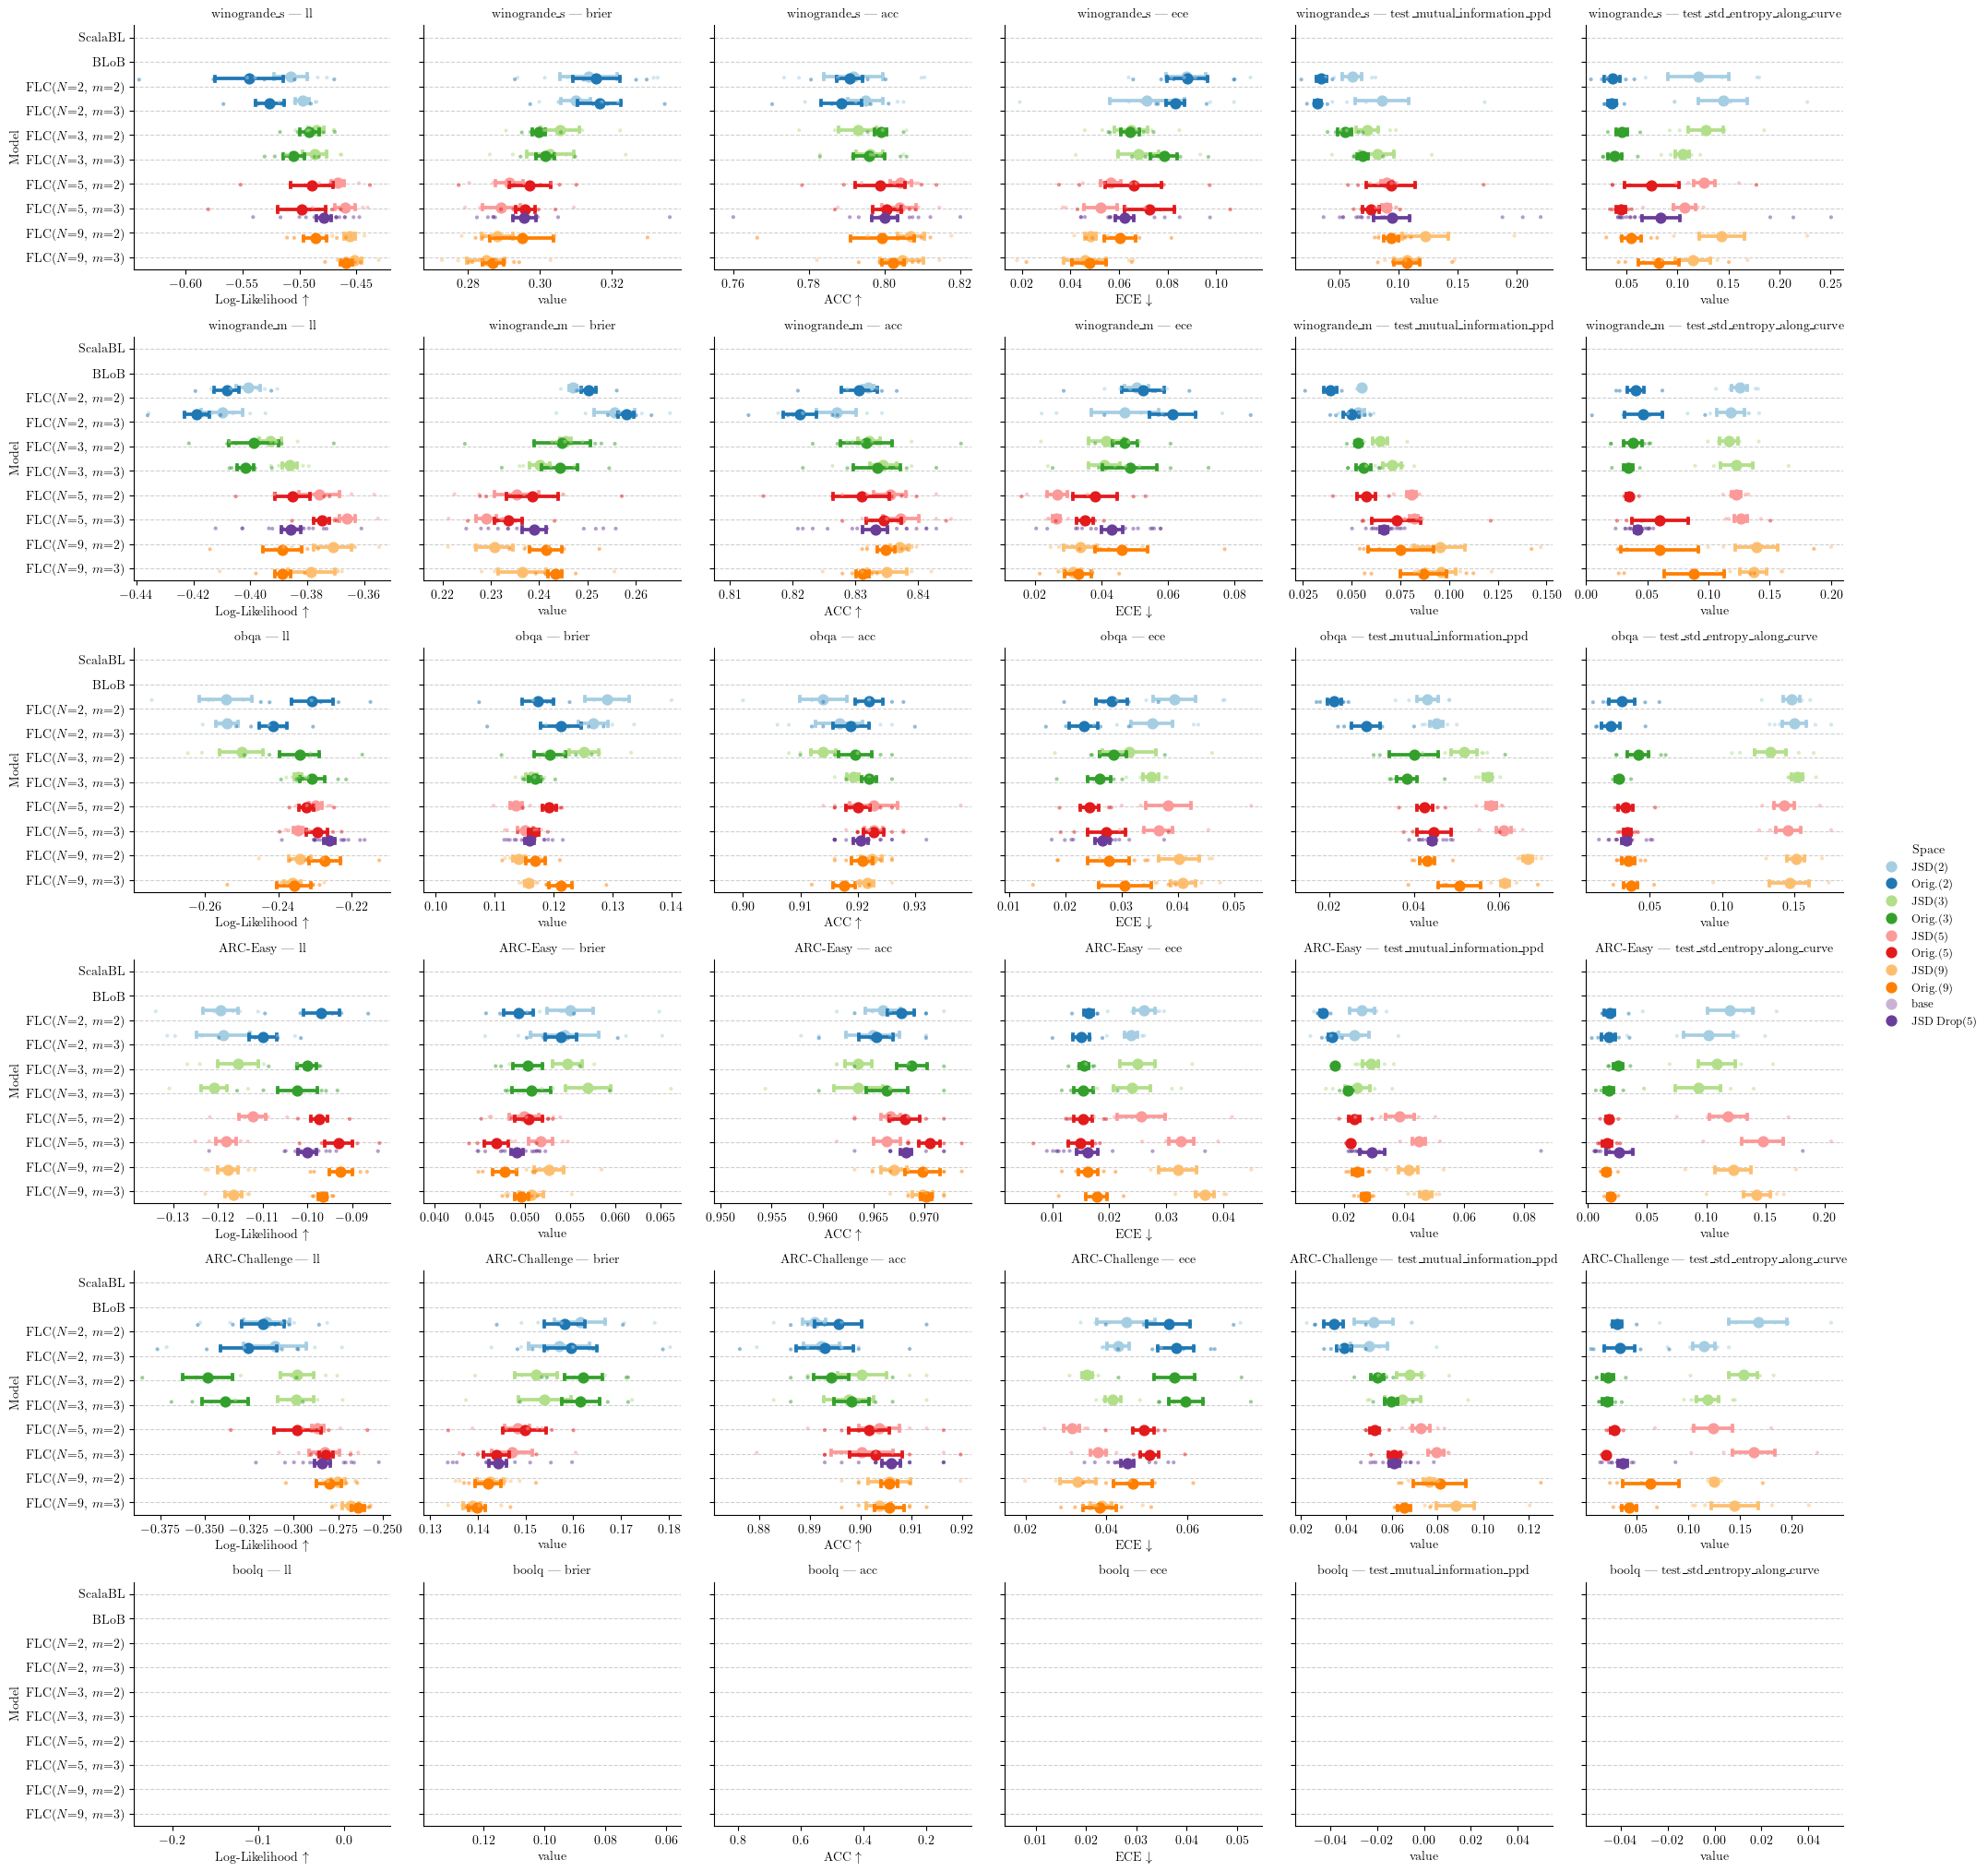

In [113]:
# stack df_vi to df_plot
hue_name = "Space"
hue_order = ['JSD(2)', 'Orig.(2)', 'JSD(3)', 'Orig.(3)', 'JSD(5)', 'Orig.(5)', 'JSD(9)', 'Orig.(9)', "base", "JSD Drop(5)"]
hue_palette = sns.color_palette("Paired")
hue_palette = {hue: hue_palette[i] for i, hue in enumerate(hue_order)}


col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = [#'MAP', 
         'ScalaBL', 'BLoB', 
        #  'Linear(3)', 'Linear(5)', 'Linear(9)', #'OpenLinear(13)',
         f'{free_model_name}({n_seg_name}=2, {seg_deg_name}=2)',
        #  f'{free_model_name}_JSD({n_seg_name}=1, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
        #  f'{free_model_name}_JSD({n_seg_name}=1, {seg_deg_name}=3)', 
         f'{free_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
        #  f'{free_model_name}_JSD({n_seg_name}=2, {seg_deg_name}=2)', 
         f'{free_model_name}({n_seg_name}=3, {seg_deg_name}=3)', 
        #  f'{free_model_name}_JSD({n_seg_name}=2, {seg_deg_name}=3)', 
         f'{free_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
        #  f'{free_model_name}_JSD({n_seg_name}=4, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)', 
        #  f'{free_model_name}_JSD({n_seg_name}=4, {seg_deg_name}=3)', 
         f'{free_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
        #  f'{free_model_name}_JSD({n_seg_name}=8, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=9, {seg_deg_name}=3)', 
         ]

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")

# # Prepare descriptive Model labels
# def get_model_label(row):
#     if str(row['Model']).startswith('DE'):
#         return f"{row['Model']}({row['NCurveSegment']})"
#     return f"{row['Model']}"

# df_plot_['Model_Label'] = df_plot_.apply(get_model_label, axis=1)

# # Ensure metric order
# metric_order = ['acc', 'll', 'ece']
# df_plot_['Metric'] = pd.Categorical(df_plot_['Metric'], categories=metric_order, ordered=True)

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    dodge=0.8,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    sharex=False, height=figsize[1], aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        dodge=0.8,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()


Models {'FLC($N$=3, $m$=2)', 'FLC($N$=2, $m$=2)', 'FLC($N$=5, $m$=2)', 'None', 'FLC($N$=9, $m$=2)'} missing:


/tmp/ipykernel_2061780/3331237598.py:32: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


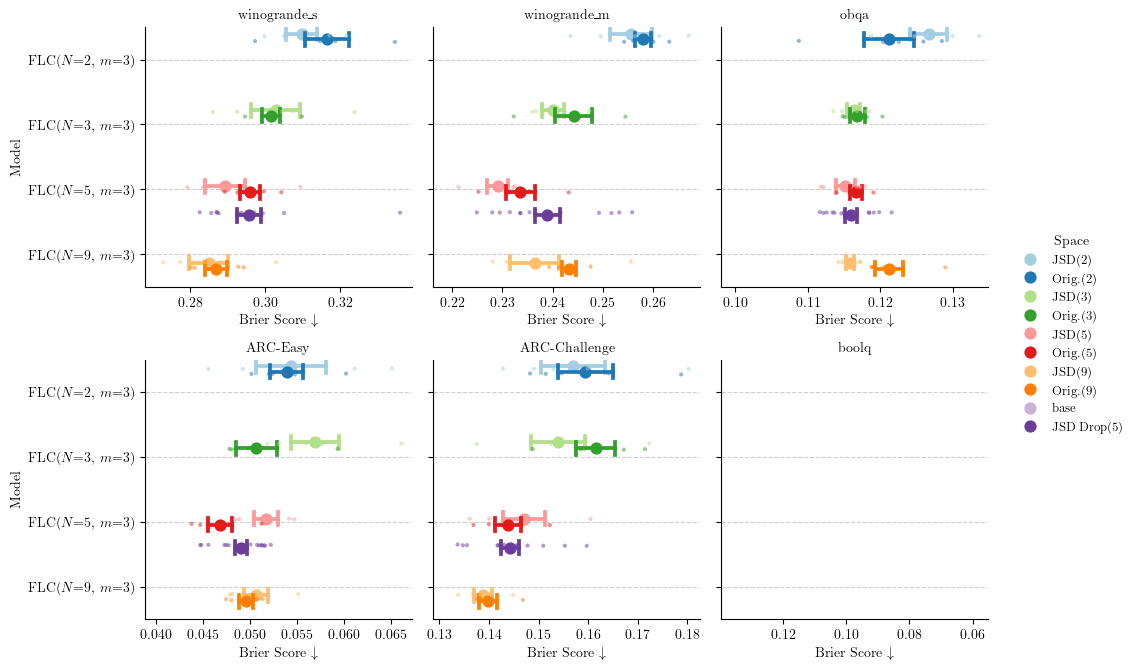

In [144]:
# stack df_vi to df_plot
hue_name = "Space"
metric = "brier"
hue_order = ['JSD(2)', 'Orig.(2)', 'JSD(3)', 'Orig.(3)', 'JSD(5)', 'Orig.(5)', 'JSD(9)', 'Orig.(9)', "base", "JSD Drop(5)"]
hue_palette = sns.color_palette("Paired")
hue_palette = {hue: hue_palette[i] for i, hue in enumerate(hue_order)}



# col_order = "ll", "brier", "acc", "ece", "test_mutual_information_ppd", "test_std_entropy_along_curve"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"
# order = df_plot_['Model'].unique()
order = [#'MAP', 
        #  'ScalaBL', 'BLoB', 
        #  f'{free_model_name}({n_seg_name}=2, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=2, {seg_deg_name}=3)', 
        #  f'{free_model_name}({n_seg_name}=3, {seg_deg_name}=2)', 
         f'{free_model_name}({n_seg_name}=3, {seg_deg_name}=3)', 
        #  f'{free_model_name}({n_seg_name}=5, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)', 
        #  f'{free_model_name}({n_seg_name}=9, {seg_deg_name}=2)',
         f'{free_model_name}({n_seg_name}=9, {seg_deg_name}=3)', 
        #  'Sampling-PSMILE', 'Sampling-SGHMC'
         ]

print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")


df_plot_subset = df_plot_[df_plot_['Metric'] == metric]

# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_subset, x='value', y='Model',
    col='Dataset', col_wrap=3,
    col_order=row_order,
    order=order,
    dodge=0.8,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    sharex=False, height=figsize[1], aspect=1.,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_subset[(df_plot_subset['Dataset'] == ds)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        dodge=0.8,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # add vertical line at BLob mean value for reference
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', label='BLoB Mean')
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')
    elif metric == 'brier':
        ax.set_xlabel(r'Brier Score $\downarrow$')
    else:
        print(f"Unknown metric {metric}, using raw name")

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.005)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
plt.show()

In [120]:
df_plot['Metric'].unique()

array(['acc', 'bezierLength', 'brier', 'ece', 'll',
       'test_mean_entropy_along_curve', 'test_mean_entropy_ppd',
       'test_mutual_information_ppd', 'test_std_entropy_along_curve'],
      dtype=object)

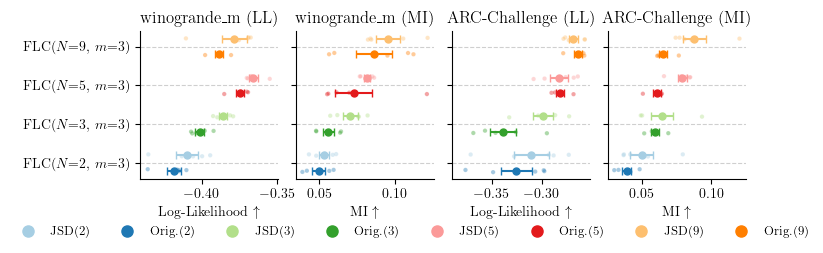

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines
import numpy as np

# Select metrics and datasets
metrics = ["ll", "test_mutual_information_ppd"]
datasets = ["winogrande_m", "ARC-Challenge"]
if "base" in hue_order:
    hue_order.remove("base")

df_plot_subset = df_plot_[
    df_plot_['Metric'].isin(metrics) & 
    df_plot_['Dataset'].isin(datasets)
].copy()

df_plot_subset = df_plot_subset[df_plot_subset['ModelMode'] != 'jsd_noise_sampling_dropout_category']

# Mapping for layout
y_mapping = {model: i for i, model in enumerate(order)}
df_plot_subset['y_base'] = df_plot_subset['Model'].map(y_mapping)

def get_offset(hue_val):
    if 'Orig' in str(hue_val):
        return -0.2
    elif 'JSD' in str(hue_val):
        return 0.2
    return 0

df_plot_subset['y_offset'] = df_plot_subset[hue_name].apply(get_offset)
df_plot_subset['y_final'] = df_plot_subset['y_base'] + df_plot_subset['y_offset']
df_plot_subset['y_scatter'] = df_plot_subset['y_final'] + np.random.uniform(-0.04, 0.04, size=len(df_plot_subset))

# Create a combined identifier for single row plotting
df_plot_subset['metric_ds'] = df_plot_subset['Metric'] + " | " + df_plot_subset['Dataset']

# Define the order of columns for the single row
col_order = [
    "ll | winogrande_m", "test_mutual_information_ppd | winogrande_m",
    "ll | ARC-Challenge", "test_mutual_information_ppd | ARC-Challenge"
]

# Create FacetGrid: 1 row, 4 columns
g = sns.FacetGrid(
    data=df_plot_subset, 
    col='metric_ds', col_order=col_order,
    sharex=False,
    height=figsize[1]/1.5, aspect=.8,
)

def custom_plot(data, **kwargs):
    ax = plt.gca()
    
    # A) Raw data
    sns.scatterplot(
        data=data, x='value', y='y_scatter',
        hue=hue_name, palette=hue_palette, hue_order=hue_order,
        alpha=0.4, s=10, legend=False, ax=ax, zorder=1
    )
    
    # B) Means & Error bars
    for hue_val in hue_order:
        sub_data = data[data[hue_name] == hue_val]
        if sub_data.empty: continue
            
        color = hue_palette[hue_val]
        grouped = sub_data.groupby('y_final')['value'].agg(['mean', 'sem']).dropna()
        
        for y_pos, row in grouped.iterrows():
            ax.errorbar(
                row['mean'], y_pos, xerr=row['sem'],
                fmt='o', color=color, markersize=5,
                capsize=3, linewidth=1.5, zorder=2
            )

g.map_dataframe(custom_plot)

# Cosmteics
for i, ax in enumerate(g.axes.flat):
    col_val = col_order[i]
    metric_type = "ll" if "ll |" in col_val else "mi"
    
    ax.set_yticks(range(len(order)))
    ax.set_yticklabels(order)  # Show y labels on all plots
    ax.invert_yaxis()
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)

    # BLoB Line
    subset = df_plot_subset[df_plot_subset['metric_ds'] == col_val]
    subset_blob = subset[subset['Model'] == 'BLoB WB']
    if not subset_blob.empty and np.isfinite(subset_blob['value'].mean()):
        ax.axvline(x=subset_blob['value'].mean(), color='gray', linestyle='--', alpha=0.5)
    
    # X-labels
    if metric_type == 'll': ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    else: ax.set_xlabel(r'MI $\uparrow$')
    
    # Title formatting
    title_parts = col_val.split(" | ")
    dataset_display = title_parts[1]
    metric_display = "LL" if title_parts[0] == "ll" else "MI"
    ax.set_title(f"{dataset_display} ({metric_display})")

    # Dynamic limits for LL
    if metric_type == 'll':
        vals = subset['value'].dropna()
        if not vals.empty:
            ax.set_xlim(left=vals.min() - 0.005, right=vals.max() + 0.005)

legend_handles = [
    mlines.Line2D([], [], color=hue_palette[hue], marker='o', linestyle='None', markersize=8, label=hue) 
    for hue in hue_order if hue in df_plot_subset[hue_name].unique()
]

g.axes[0,0].set_ylabel("")
# Adjust legend and layout
g.add_legend(handles=legend_handles, title="", loc='lower left', bbox_to_anchor=(-0.02, -0.11), ncol=9)
g.fig.subplots_adjust(bottom=0.2)

plt.savefig("result/performance_jsd.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/figures/performance_jsd.pdf", dpi=300, bbox_inches='tight')

plt.show()

### Flat Lora Compare

In [153]:
import wandb
from tqdm import tqdm
from copy import deepcopy
import numpy as np

api = wandb.Api()
results = []


for s in set(["w0kaq8i0", 'xv7jw9bv', 'we8wq8n7', 'jb3j4w2y' ]): # + flat lora winogrande_m training 
    t_run = tqdm(api.sweep(f"ddold/qwen_PtoC_newDS/{s}").runs)
    t_run.set_description(s)
    for run in t_run:
        if run.state != 'finished':
            print(f"Skipping {run.name} because it is not finished")
            continue
        t_run.set_postfix_str(run.name)
        mp = run.config['model_params']
        opt_conf = run.config['optimizer_conf']
        hp = run.config['train_hyper']
        lora = mp['lora_params']

        NCurveSegment = mp['num_curve_segment']
        CurveDegree = mp['SegDeg']
        res = dict(Id=run.id,
        #    CurveSpace=f"{mp['k']}",
            # CurveSpace=len(mp['cp_fix']),
            CurveSpace=NCurveSegment * CurveDegree,
            # CpFix=str(mp['cp_fix']),
            NumPretrained=NCurveSegment + 1 if mp['Pretraining'] else 0,
            Jitter=mp['jitter_multiplier'],
            Seed=run.config['rng_seed'],
            WeightDecay=opt_conf['kwargs']['weight_decay'],
            Dataset="_".join(run.config['data']['dataset_path'].split('/')[-1].split('.')[0].split('_')[:-1]),
            BmaMode="PPD",
            DS_Sampling=list(hp.get('dataset_sampling', {'None': None}).keys())[0],
            DS_Mode=str(hp['dataset_sampling'].get('expert', {'sort_mode': 'classic'}).get('sort_mode', 'None')),
            DS_WindowSize=hp['dataset_sampling'].get('expert', {'window_size': -1}).get('window_size', -1),
            EntropyMaxScale=mp.get('entropy_maxim', -1),
            NumSteps=hp.get('num_steps', -1),
            LoraMode=lora.get('lora_mode', 'None'),
            CurveMode=mp.get('curve_parameterization', 'Bezier'),
            LoraRank=lora.get('r', -1),
            RegularizationMode=mp.get('regularizer', False),
            Gravity=mp.get('gravity', 0.),
            EnergyWeakening=mp.get('energy_weakening', 0.),
            Tsample=mp.get('curve_sampling_mode', 'None'),
            LoraRho=lora.get('lora_rho', -1),
            LoraRhoS=lora.get('lora_rho_s', -1),
            RhoFrequency=lora.get('rho_scheduler_frequency', 0),
            CurveSegmentDegree=CurveDegree,
            NCurveSegment=NCurveSegment,
            OpenEndSegment=mp.get('independent_connected', False),
            bezierLength=run.summary.get('Curve length', 0),
            acc=run.summary.get(f"test_ppd_acc", -np.inf),
            ece=run.summary.get(f"test_ppd_ece", -np.inf),
            ll=run.summary.get(f"test_ppd_ll", -np.inf),
            brier=run.summary.get(f"test_ppd_brier", -np.inf),
            test_mean_entropy_ppd=run.summary.get(f"test_ppd_weighted_mean_entropy", -np.inf),
            test_mutual_information_ppd=run.summary.get(f"test_ppd_weighted_mutual_information", -np.inf),
            test_std_entropy_along_curve=0,
            test_mean_entropy_along_curve=0,
            )
        results.append(res)
        if mp['Pretraining']:
            # add DE   
            _res = deepcopy(res)
            _res['BmaMode'] = "DE"
            _res['acc'] = run.summary.get(f"test_DE_acc", -np.inf)
            _res['ece'] = run.summary.get(f"test_DE_ece", -np.inf)
            _res['ll'] = run.summary.get(f"test_DE_ll", -np.inf)
            _res['brier']=run.summary.get(f"test_DE_brier", -np.inf)
            _res['test_mean_entropy_ppd']=run.summary.get(f"test_DE_uniform_mean_entropy", -np.inf)
            _res['test_mutual_information_ppd']=run.summary.get(f"test_DE_uniform_mutual_information", -np.inf)
            _res['test_std_entropy_along_curve']=run.summary.get(f"test_DE_uniform_std_entropy_along_curve", -np.inf)
            _res['test_mean_entropy_along_curve']=run.summary.get(f"test_DE_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)
            for k in run.summary.keys():
                if k.startswith("cp_fixed_") and k.endswith("_test_acc"):
                    i = k.split("_")[2]
                    _res = deepcopy(res)
                    _res['BmaMode'] = "MAP"
                    # print(run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf))
                    _res['acc'] = run.summary.get(f"cp_fixed_{i}_test_acc", -np.inf)
                    _res['ece'] = run.summary.get(f"cp_fixed_{i}_test_ece", -np.inf)
                    _res['ll'] = run.summary.get(f"cp_fixed_{i}_test_ll", -np.inf)
                    _res['brier']=run.summary.get(f"cp_fixed_{i}_test_brier", -np.inf)
                    _res['test_mean_entropy_ppd']=run.summary.get(f"cp_fixed_{i}_test_entropy", -np.inf)
                    _res['test_mutual_information_ppd']=0
                    _res['test_std_entropy_along_curve']=0
                    _res['test_mean_entropy_along_curve']=0
                    # print(_res['acc'], _res['ece'], _res['ll'])
                    results.append(_res)

        # add PPD uniform   
        _res = deepcopy(res)
        _res['BmaMode'] = "PPD Uniform"
        _res['acc'] = run.summary.get(f"test_ppd_uniform_acc", -np.inf)
        _res['ece'] = run.summary.get(f"test_ppd_uniform_ece", -np.inf)
        _res['ll'] = run.summary.get(f"test_ppd_uniform_ll", -np.inf)
        _res['brier']=run.summary.get(f"test_ppd_uniform_brier", -np.inf)
        _res['test_mean_entropy_ppd']=run.summary.get(f"test_ppd_uniform_mean_entropy", -np.inf)
        _res['test_mutual_information_ppd']=run.summary.get(f"test_ppd_uniform_mutual_information", -np.inf)
        _res['test_std_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_std_entropy_along_curve", -np.inf)
        _res['test_mean_entropy_along_curve']=run.summary.get(f"test_ppd_uniform_mean_entropy_along_curve", -np.inf)
        results.append(_res)
 
df = pd.DataFrame(results)
df.describe().T

xv7jw9bv:   0%|          | 0/50 [00:00<?, ?it/s, peach-sweep-31]   

w0kaq8i0: 100%|██████████| 200/200 [00:00<00:00, 303.99it/s, colorful-sweep-6]      
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/pandas/core/nanops.py:1016: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
/home/daniel/miniconda3/envs/jaxTorchTrans/lib/python3.10/site-packages/numpy/lib/function_base.py:4655: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


,count,mean,std,min,25%,50%,75%,max
CurveSpace,2450.0,1.137755e+01,6.724035,2.000000e+00,6.000000,12.000000,16.000000,24.000000
NumPretrained,2450.0,4.408163e+00,3.175282,0.000000e+00,2.000000,5.000000,5.000000,9.000000
Jitter,2450.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
Seed,2450.0,1.684600e+03,3162.006447,1.000000e+00,2.000000,20.000000,400.000000,8000.000000
WeightDecay,2450.0,1.000000e-03,0.000000,1.000000e-03,0.001000,0.001000,0.001000,0.001000
DS_WindowSize,2450.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
EntropyMaxScale,2450.0,-1.000000e+00,0.000000,-1.000000e+00,-1.000000,-1.000000,-1.000000,-1.000000
NumSteps,2450.0,1.000000e+04,0.000000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000
LoraRank,2450.0,8.000000e+00,0.000000,8.000000e+00,8.000000,8.000000,8.000000,8.000000
Gravity,2450.0,0.000000e+00,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000


In [154]:
# get all colum names that starts with capital letter
cols = [col for col in df.columns if col[0].isupper()]
# runs with problems
idx_config_with_nan = df.isnull().values.any(axis=1)
df[idx_config_with_nan].set_index(cols)

df_clean = df[~idx_config_with_nan]
idx_ids = [col for col in df.columns if col[0].isupper()]
value_ids = np.setdiff1d(df.columns.values, idx_ids)
print("Unique configuartions: ")
variable_idx = []
for c in df_clean.columns:
    if c not in [*value_ids, 'Id']:
        unique_ = df_clean[c].unique()
        print(c, unique_)
        if (len(unique_) > 1) and( c != 'Seed'):
            variable_idx.append(c)
print(f"\nExperiment differs in {variable_idx} configs")
col_order = df_clean['Dataset'].unique()
col_order.sort()
col_order

Unique configuartions: 
CurveSpace [12 24  6  3 16  8  4  2]
NumPretrained [0 9 5 3 2]
Jitter [0]
Seed [8000  400   20    2    1]
WeightDecay [0.001]
Dataset ['ARC-Easy' 'ARC-Challenge' 'winogrande_s' 'obqa' 'winogrande_m']
BmaMode ['PPD' 'PPD Uniform' 'DE' 'MAP']
DS_Sampling ['minibatch']
DS_Mode ['classic']
DS_WindowSize [-1]
EntropyMaxScale [-1]
NumSteps [10000]
LoraMode ['A(t)eB(t)']
CurveMode ['bezier']
LoraRank [8]
RegularizationMode [False]
Gravity [0]
EnergyWeakening [1]
Tsample ['combined_all']
LoraRho [0.5  0.   0.25]
LoraRhoS [0]
RhoFrequency [50]
CurveSegmentDegree [3 2]
NCurveSegment [4 8 2 1]
OpenEndSegment [False]

Experiment differs in ['CurveSpace', 'NumPretrained', 'Dataset', 'BmaMode', 'LoraRho', 'CurveSegmentDegree', 'NCurveSegment'] configs


array(['ARC-Challenge', 'ARC-Easy', 'obqa', 'winogrande_m',
       'winogrande_s'], dtype=object)

In [155]:
# Build Config label
df_subset = df_clean.copy()
# df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'MAP')]
df_subset = df_subset[(df_subset['LoraMode'] == "A(t)eB(t)") & (df_subset['BmaMode'] != 'PPD')]

# Filter for only configs with LoraRho=0.0 (open curves) and then inner join back to keep only those configs across all seeds and metrics
match_cols = deepcopy(variable_idx) + ['Seed']
match_cols.remove('LoraRho')
filter_mask = df_subset[df_subset['LoraRho'] == 0.][match_cols].drop_duplicates()
df_subset = df_subset.merge(filter_mask, on=match_cols, how='inner')

df_plot = df_subset.melt(id_vars=idx_ids, value_vars=value_ids, var_name='Metric', value_name='value')
# df_plot['Config'] = df_plot.apply(lambda r: f"fix={r['NumPretrained']}, k={r['CurveSpace']}, SegDeg={r['CurveSegmentDegree']}, N_Seg={r['NCurveSegment']}, rho={r['LoraRho']}, Mode={r['LoraMode']}/{r['CurveMode']}", axis=1)
df_plot['Config'] = df_plot.apply(lambda r: " | ".join([f"{k}={r[k]}" for k in variable_idx if k not in ['CurveSpace', 'NCurveSegment', 'NumPretrained', 'Dataset', 'BmaMode',]]), axis=1)

def map_model(x):
    if x['BmaMode'] == 'MAP':
        return "MAP"
    elif x['BmaMode'] == 'DE':
        return f"DE({n_seg_name}={x['NumPretrained']})"
    elif x['BmaMode'] == 'PPD Uniform':
        is_fixed = x['NumPretrained'] > 0
        seg_deg = x['CurveSegmentDegree']
        
        if seg_deg == 1:
            prefix = "Linear" if is_fixed else "Linear_" + free_model_name
            return f"{prefix}({n_seg_name}={x['NumPretrained']})"
        else:
            prefix = pretrained_model_name if is_fixed else free_model_name
            return rf"{prefix}({n_seg_name}={x['NCurveSegment'] + 1}, {seg_deg_name}={seg_deg})"
    else:
        return "None"

df_plot['Model'] = df_plot.apply(map_model, axis=1)
# set NCurveSegment to 0 for MAP and DE
df_plot.loc[df_plot['BmaMode'] == 'MAP', 'NCurveSegment'] = 0
df_plot.loc[df_plot['BmaMode'] == 'DE', 'NCurveSegment'] = 0
df_plot.sort_values(by=['Model'], inplace=True)

col_order = df_subset['Dataset'].unique()
col_order.sort()


Models set() missing:


/tmp/ipykernel_2061780/505897511.py:25: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


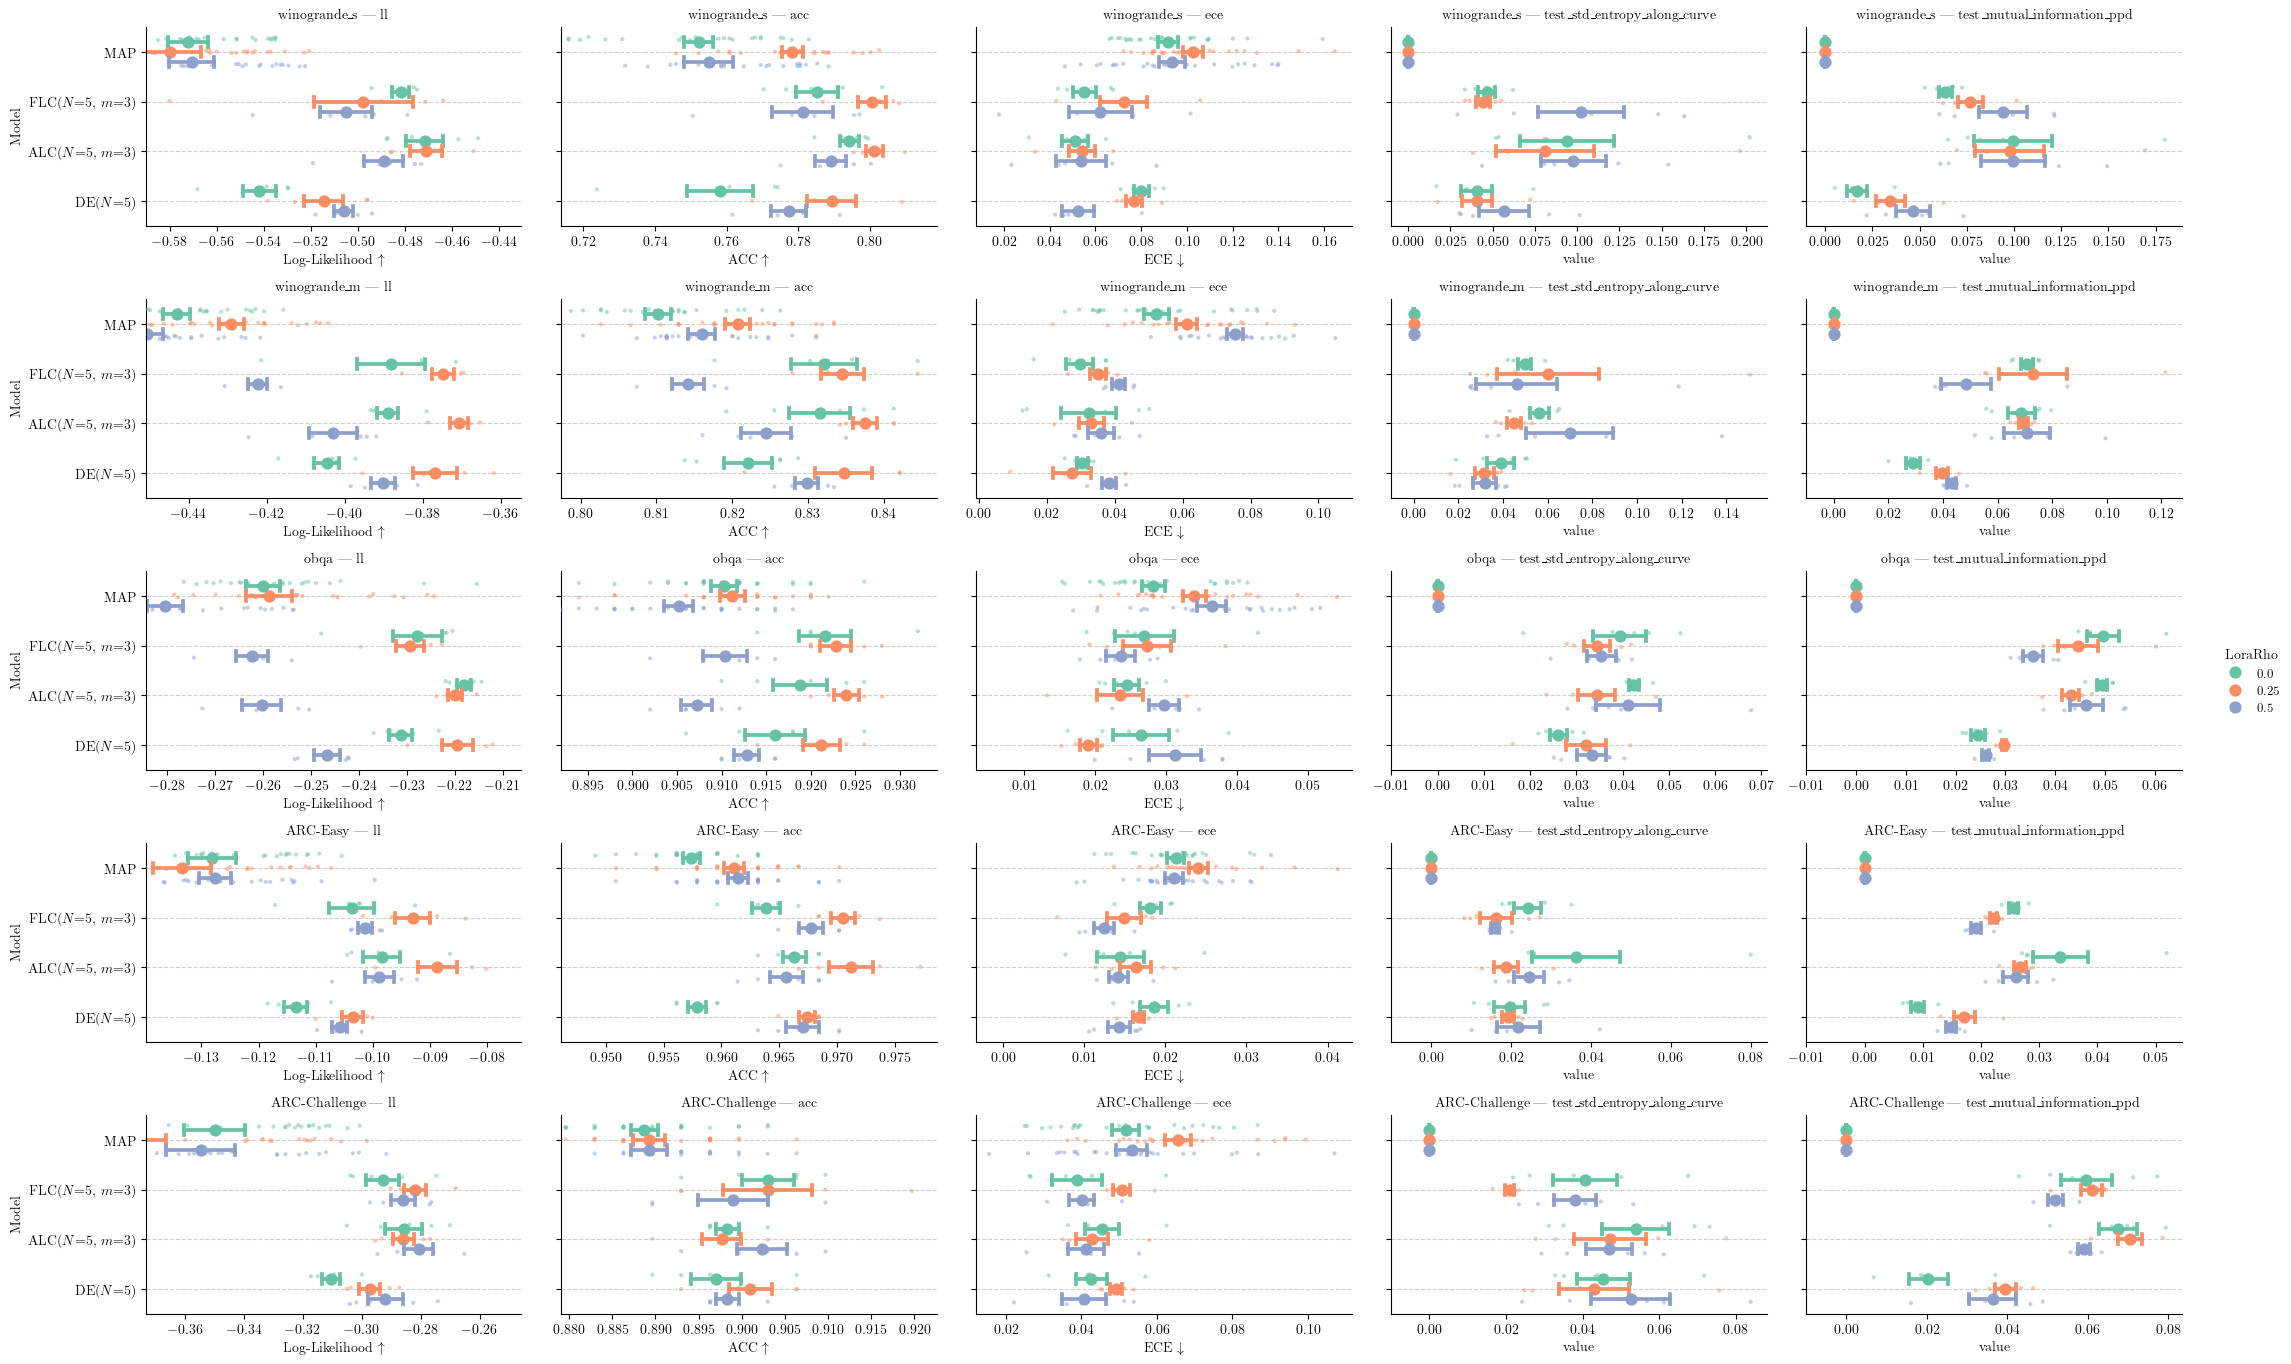

In [156]:
# stack df_vi to df_plot
hue_name = 'LoraRho'
df_plot_ = deepcopy(df_plot)
df_plot_[hue_name] = df_plot_[hue_name].astype(float)
# df_plot_ = pd.concat([df_plot,], ignore_index=True)
# hue
numeric_rhos = sorted(float(x) for x in df_plot_[hue_name].unique())
df_plot_[hue_name] = df_plot_[hue_name].astype(str)
hue_order = [str(x) for x in numeric_rhos]
hue_palette = sns.color_palette("Set2", n_colors=len(hue_order))
col_order = "ll", "acc", "ece", "test_std_entropy_along_curve", "test_mutual_information_ppd"
row_order = "winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge",
order = df_plot_['Model'].unique()
order = ['MAP',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
         rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         f'DE({n_seg_name}=5)']


print(f"Models {set(df_plot_['Model'].unique()) - set(order)} missing:")


# Seaborn Catplot (ANOVA style)
g = sns.catplot(
    data=df_plot_, x='value', y='Model',
    row='Dataset', col='Metric',
    row_order=row_order, col_order=col_order,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.4, sharex=False, height=figsize[0]/2, aspect=1.618,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for (ds, metric), ax in g.axes_dict.items():
    subset = df_plot_[(df_plot_['Dataset'] == ds) & (df_plot_['Metric'] == metric)]
    sns.stripplot(
        data=subset, x='value', y='Model',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.4, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='y', linestyle='--', alpha=0.6)
    
    # Label mapping for x-axis
    if metric == 'acc':
        ax.set_xlabel(r'ACC $\uparrow$')
    elif metric == 'll':
        ax.set_xlabel(r'Log-Likelihood $\uparrow$')
    elif metric == 'ece':
        ax.set_xlabel(r'ECE $\downarrow$')

    # clip x-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    min_value = only_finit(subset[subset['Model'] != 'MAP']['value']).min()
    mean_value_MAP = only_finit(subset[subset['Model'] == 'MAP']['value']).mean()
    if np.isfinite(min_value):
        ax.set_xlim(left=min(min_value, mean_value_MAP)-0.01)  # add some padding on the left

# Adjust layout and titles
g.set_titles(row_template='{row_name}', col_template='{col_name}')
g.tight_layout()
# g.add_legend(title='#CurveSegments')
# plt.savefig("result/performance_pointplot.png", dpi=300)
# plt.savefig("result/performance_pointplot.pdf", dpi=300)
plt.show()

/tmp/ipykernel_2061780/1010608345.py:12: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


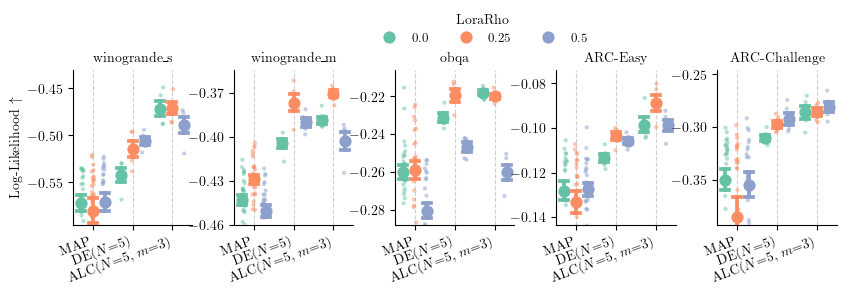

In [164]:
# Only LL metric plotted with col='Dataset' and col_wrap=3
df_plot_ll = df_plot_[df_plot_['Metric'] == 'll'].copy()

col_order_ds = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge"]
order = ['MAP',
         f'DE({n_seg_name}=5)',
        #  f'Linear({n_seg_name}=5)', #'OpenLinear(13)',
        #  rf'{free_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         rf'{pretrained_model_name}({n_seg_name}=5, {seg_deg_name}=3)',
         ]

g = sns.catplot(
    data=df_plot_ll, x='Model', y='value',
    col='Dataset', col_wrap=5,
    col_order=col_order_ds,
    order=order,
    kind='point', join=False, capsize=.2,
    markers='o', palette=hue_palette, hue=hue_name,
    dodge=0.6, sharey=False, height=figsize[1]/1.5, aspect=0.8,
    legend=True, errorbar="se", hue_order=hue_order,
)

# Overlay strip plots for original points (small, alpha=0.5)
for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll['Dataset'] == ds]
    sns.stripplot(
        data=subset, x='Model', y='value',
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=3,
        dodge=0.6, hue=hue_name, legend=False, hue_order=hue_order,
    )
    
    # Refine grid and labels
    ax.grid(True, axis='x', linestyle='--', alpha=0.6)
    
    # Label mapping for y-axis
    ax.set_ylabel(r'Log-Likelihood $\uparrow$')
    ax.set_xlabel('')

    # clip y-axis to range of min without MAP
    def only_finit(x):
        return x[np.isfinite(x)]
    
    non_map_vals = only_finit(subset[subset['Model'] != 'MAP']['value'])
    map_vals = only_finit(subset[subset['Model'] == 'MAP']['value'])
    
    min_value = non_map_vals.min() if not non_map_vals.empty else np.nan
    mean_value_MAP = map_vals.mean() if not map_vals.empty else np.nan
    mean_value_MAP  = np.quantile(map_vals, 0.25) if not map_vals.empty else np.nan  # use 25th percentile to be more robust against outliers
    
    if np.isfinite(min_value) and np.isfinite(mean_value_MAP):
        ax.set_ylim(bottom=min(min_value, mean_value_MAP)-0.01)  # add some padding on the bottom
    elif np.isfinite(min_value):
        ax.set_ylim(bottom=min_value-0.01)

# Adjust layout and titles
g.set_titles(col_template='{col_name}')
g.tight_layout()

#legent top flat
sns.move_legend(g, loc='upper center', bbox_to_anchor=(0.5, 1.15), ncol=len(hue_order), title=hue_name)
# rotate x labels
for i, ax in enumerate(g.axes):
    plt.setp(ax.get_xticklabels(), rotation=20, ha='right')
    # plt.setp(ax.get_yticklabels(), rotation=20, ha='right')
    if i > 0:
        ax.set_ylabel('')  # remove x-axis label since it's redundant with the rotated labels
# set wspace
g.axes[1].set_yticks([-0.37, -0.4, -0.43, -0.46])  # remove y-ticks for middle plot to save space
g.fig.subplots_adjust(wspace=0.35)


plt.savefig("result/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')
plt.savefig("my-overleaf-project/figures/performance_flatLoRA_vs_vanilla.pdf", dpi=300, bbox_inches='tight')
plt.show()